# Spec-driven development in GitHub repositories

CSU CS 440 final project · cleaned SpecMine exploratory analysis

**Questions:** RQ1 repository profiles; RQ2 repository age at first detection; RQ3 detections and category use over time.

First detected specification commits are a **proxy for adoption**. These tables contain detected SDD repositories, without a GitHub-wide comparison population. Counts and shares describe this sample, not overall GitHub adoption rates or causal effects. Data end in **July 2026**; July and 2026 are partial.

The repository table has one row per repository. The category table has one row per repository-category pair, and memberships overlap. Generic categories such as `root_bare` and `docs_embedded` are not software products. All analyses follow `DATA_COLUMNS.md`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'data/repo_summary.csv').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown, Image
from src.data import load_data
from src.statistics import summary_tables
from src.plotting import set_style
from src import repository_plots as rp, tool_plots as tp

print((ROOT / 'DATA_COLUMNS.md').read_text(encoding='utf-8'))
data = load_data(ROOT)  # validation precedes all analysis
r, t = data.repositories, data.tools
tables = summary_tables(data)
OUT = ROOT / 'figures'
set_style()

def show(chart):
    display(Image(filename=str(chart.path), width=950))
    display(Markdown('**Caption.** ' + chart.caption + '\n\n**Interpretation.** ' + chart.interpretation))

display(Markdown(f'Validated **{len(r):,} repositories** and **{len(t):,} repository-category pairs** across **{t.repo_name.nunique():,} unique repositories**.'))
display(tables['age_status_audit'])
display(Markdown('**Input SHA-256 fingerprints:** ' + str(data.audit['input_sha256'])))

# Data Column Guide

This file explains the processed CSV files created by `build_datasets.py`.

## repo_summary.csv

Each row represents one GitHub repository found in the SpecMine dataset.

- `repo_name` - GitHub repository name in `owner/repository` format.
- `repo_language` - Main programming language reported by GitHub.
- `owner_type` - Type of repository owner, such as `User` or `Organization`.
- `repo_stars` - Number of GitHub stars the repository has.
- `repo_forks` - Number of times the repository has been forked.
- `repo_fork` - Whether the repository itself is a fork (`True` or `False`).
- `repo_created_at` - Date and time the GitHub repository was created.
- `first_sdd_at` - Earliest detected commit date for an SDD specification in the repository.
- `num_specs` - Number of unique SDD specification files detected in the repository.
- `num_sdd_tools` - Number of different SDD tool categories detected in the repository.
- `sdd_tools` - List of SDD tool categories detected in t

Validated **73,031 repositories** and **75,866 repository-category pairs** across **73,031 unique repositories**.

,grain,status,records,included_in_age_analysis
0,repository,valid,57164,True
1,repository,predates_repo_creation,15680,False
2,repository,missing_date,187,False
3,repository-category,valid,59617,True
4,repository-category,predates_repo_creation,16051,False
5,repository-category,missing_date,198,False


**Input SHA-256 fingerprints:** {'repo_summary.csv': '747a92f9c9d92ce01e868b303237ceb54e729ac4c7d61fb973cef635dedc39bb', 'repo_tool_adoption.csv': 'e95ff4eeb81eea20b222a516185d89d7247f3874a44aa679c45f997e73a43114'}

## RQ1: What types of GitHub repositories use detected SDD?

Use every repository row, irrespective of adoption-age status. Numeric summaries retain all nonmissing observations and outliers. Logged-in specification contributor counts refer to unique GitHub accounts committing to detected specification files, not the entire repository contributor population.

In [2]:
display(tables['numeric_summary'].query("grain == 'repository'"))

,grain,variable,n_non_null,n_missing,median,mean,q25,q75,maximum
0,repository,repo_stars,73031,0,0.0,31.081226,0.0,0.0,75672.0
1,repository,repo_forks,73031,0,0.0,4.474525,0.0,0.0,15505.0
2,repository,num_specs,73031,0,1.0,6.446509,1.0,2.0,2708.0
3,repository,num_sdd_tools,73031,0,1.0,1.038819,1.0,1.0,6.0
4,repository,num_logged_in_spec_contributors,73031,0,1.0,0.783393,0.0,1.0,36.0


### Top languages and missingness

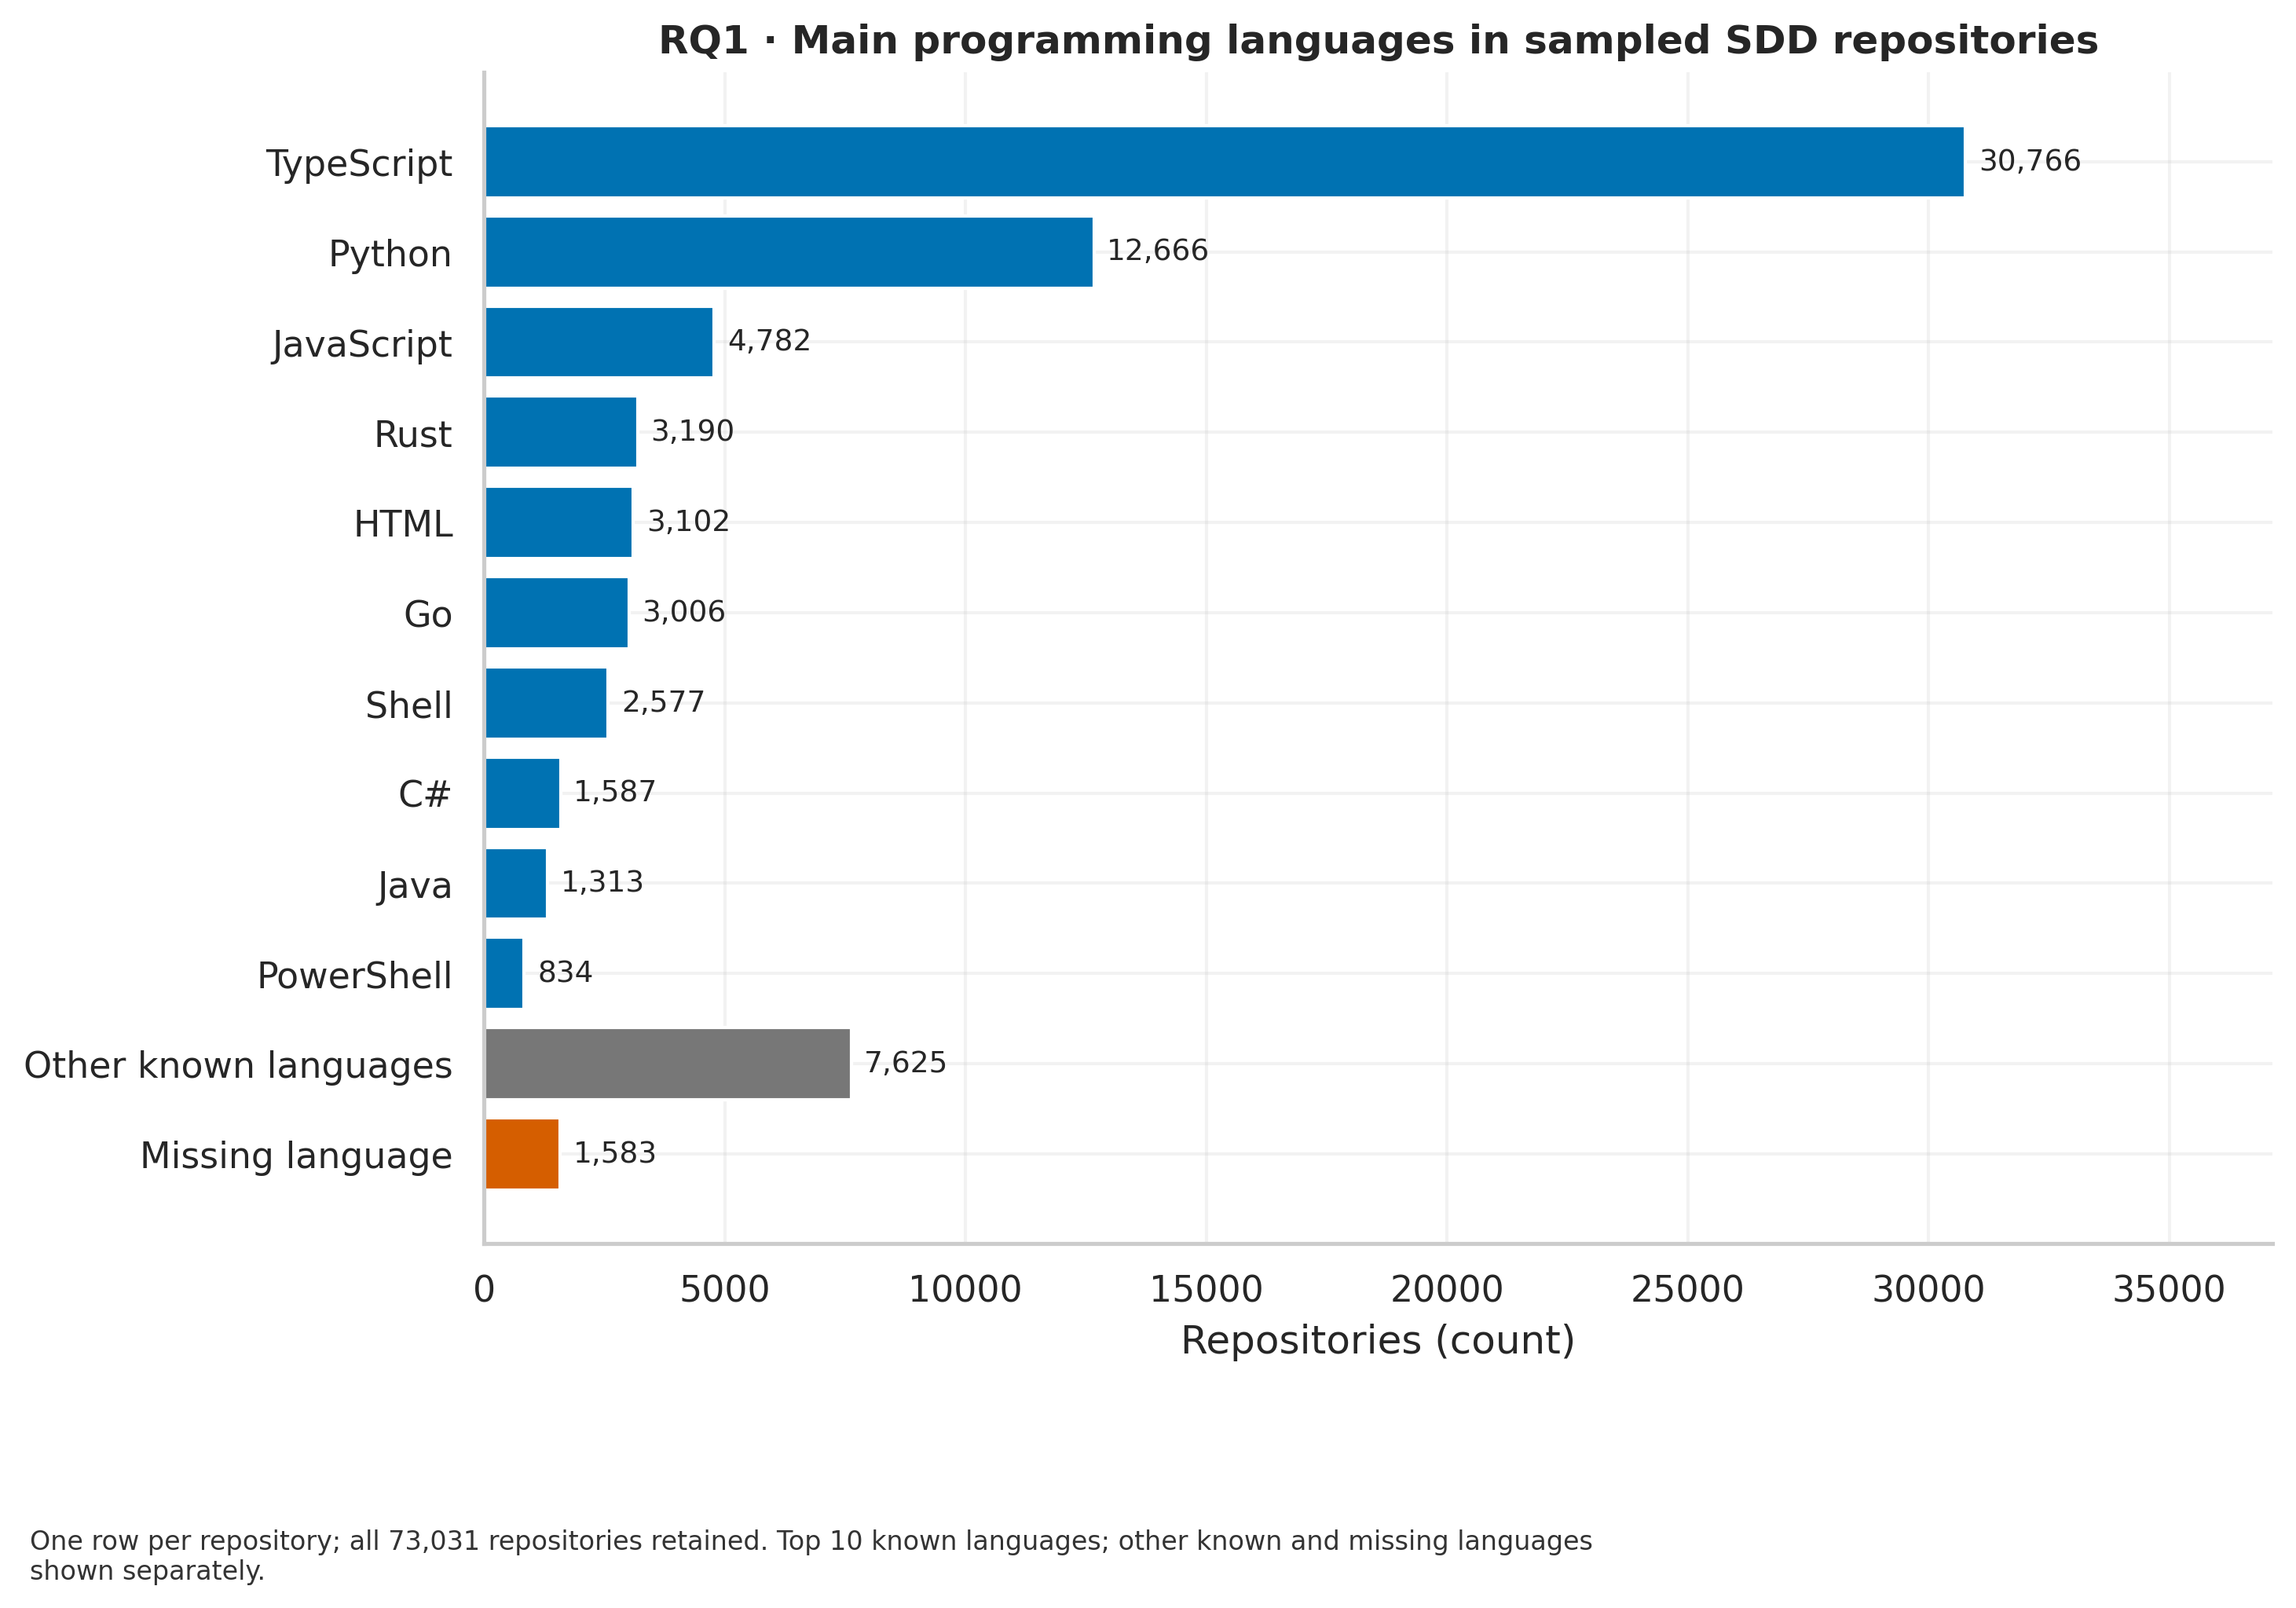

**Caption.** One row per repository; all 73,031 repositories retained. Top 10 known languages; other known and missing languages shown separately.

**Interpretation.** TypeScript is the most frequent main language (30,766 repositories; 42.1% of this sample). Language is missing for 1,583 repositories.

In [3]:
show(rp.languages(r, OUT))

### Repository owner types

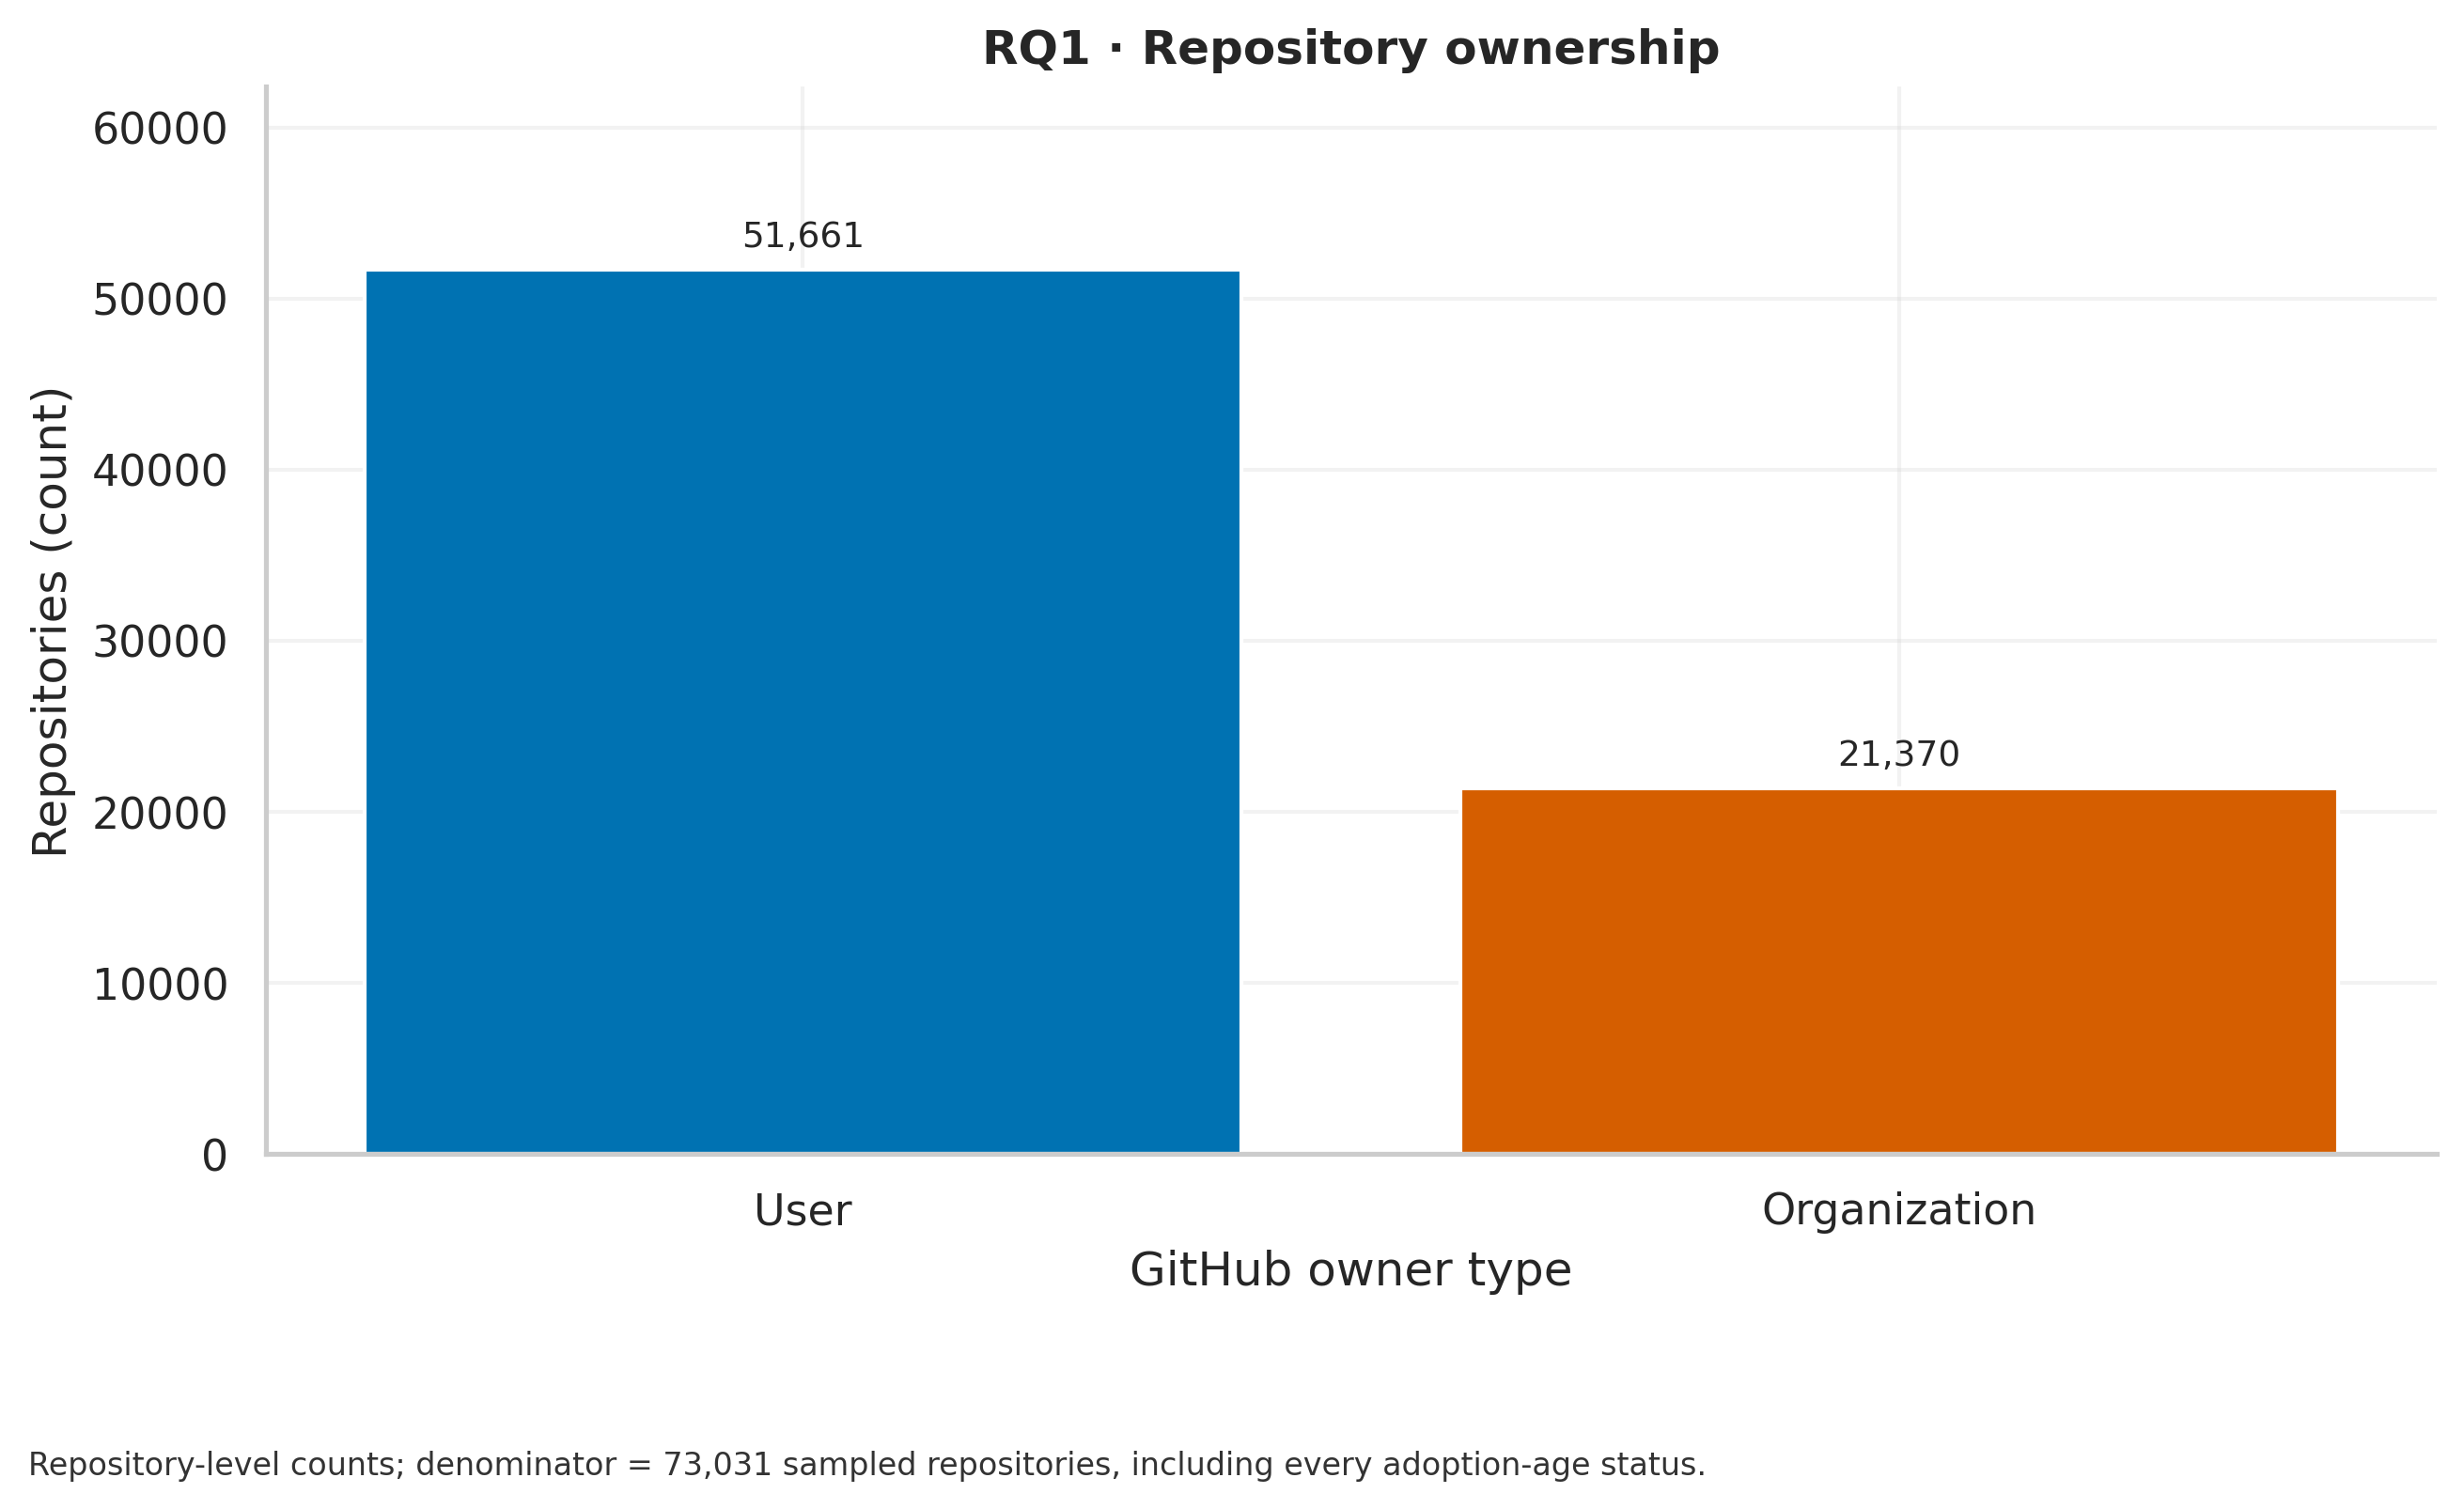

**Caption.** Repository-level counts; denominator = 73,031 sampled repositories, including every adoption-age status.

**Interpretation.** User: 51,661 (70.7%); Organization: 21,370 (29.3%). These are sample shares.

In [4]:
show(rp.ownership(r, OUT))

### Stars and forks received

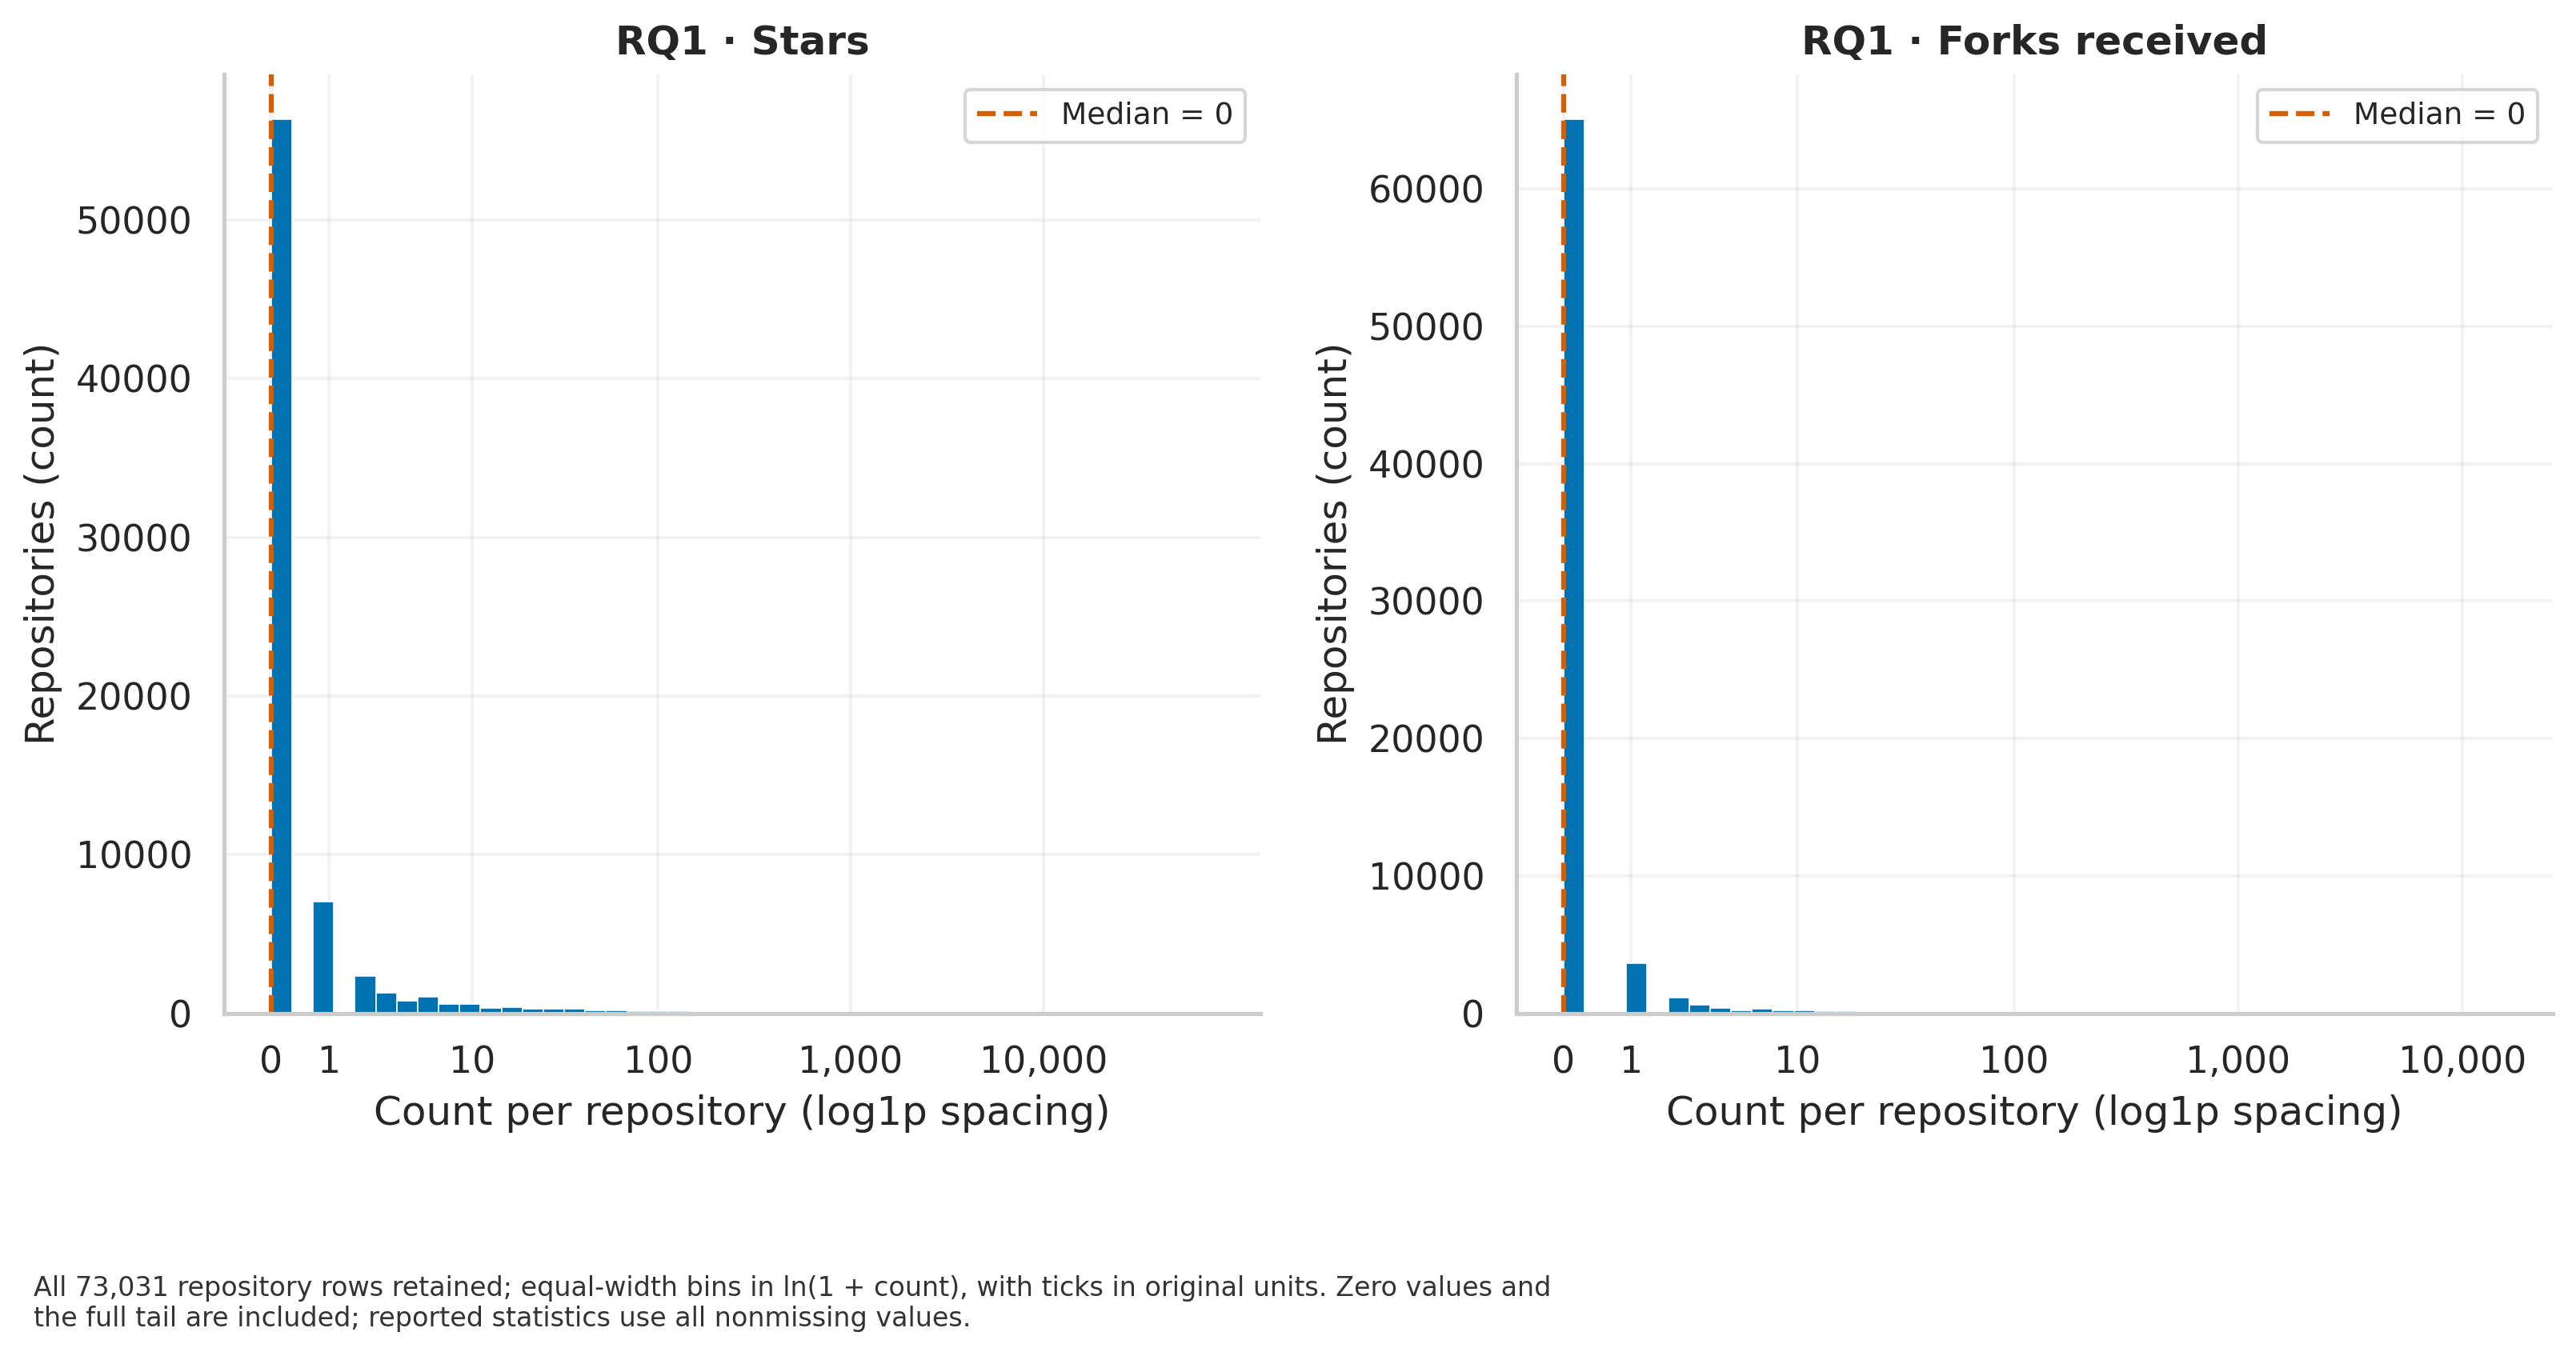

**Caption.** All 73,031 repository rows retained; equal-width bins in ln(1 + count), with ticks in original units. Zero values and the full tail are included; reported statistics use all nonmissing values.

**Interpretation.** RQ1 · Stars: median 0, mean 31.08, maximum 75,672 (n=73,031). RQ1 · Forks received: median 0, mean 4.47, maximum 15,505 (n=73,031).

In [5]:
show(rp.popularity(r, OUT))

### Specification files per repository

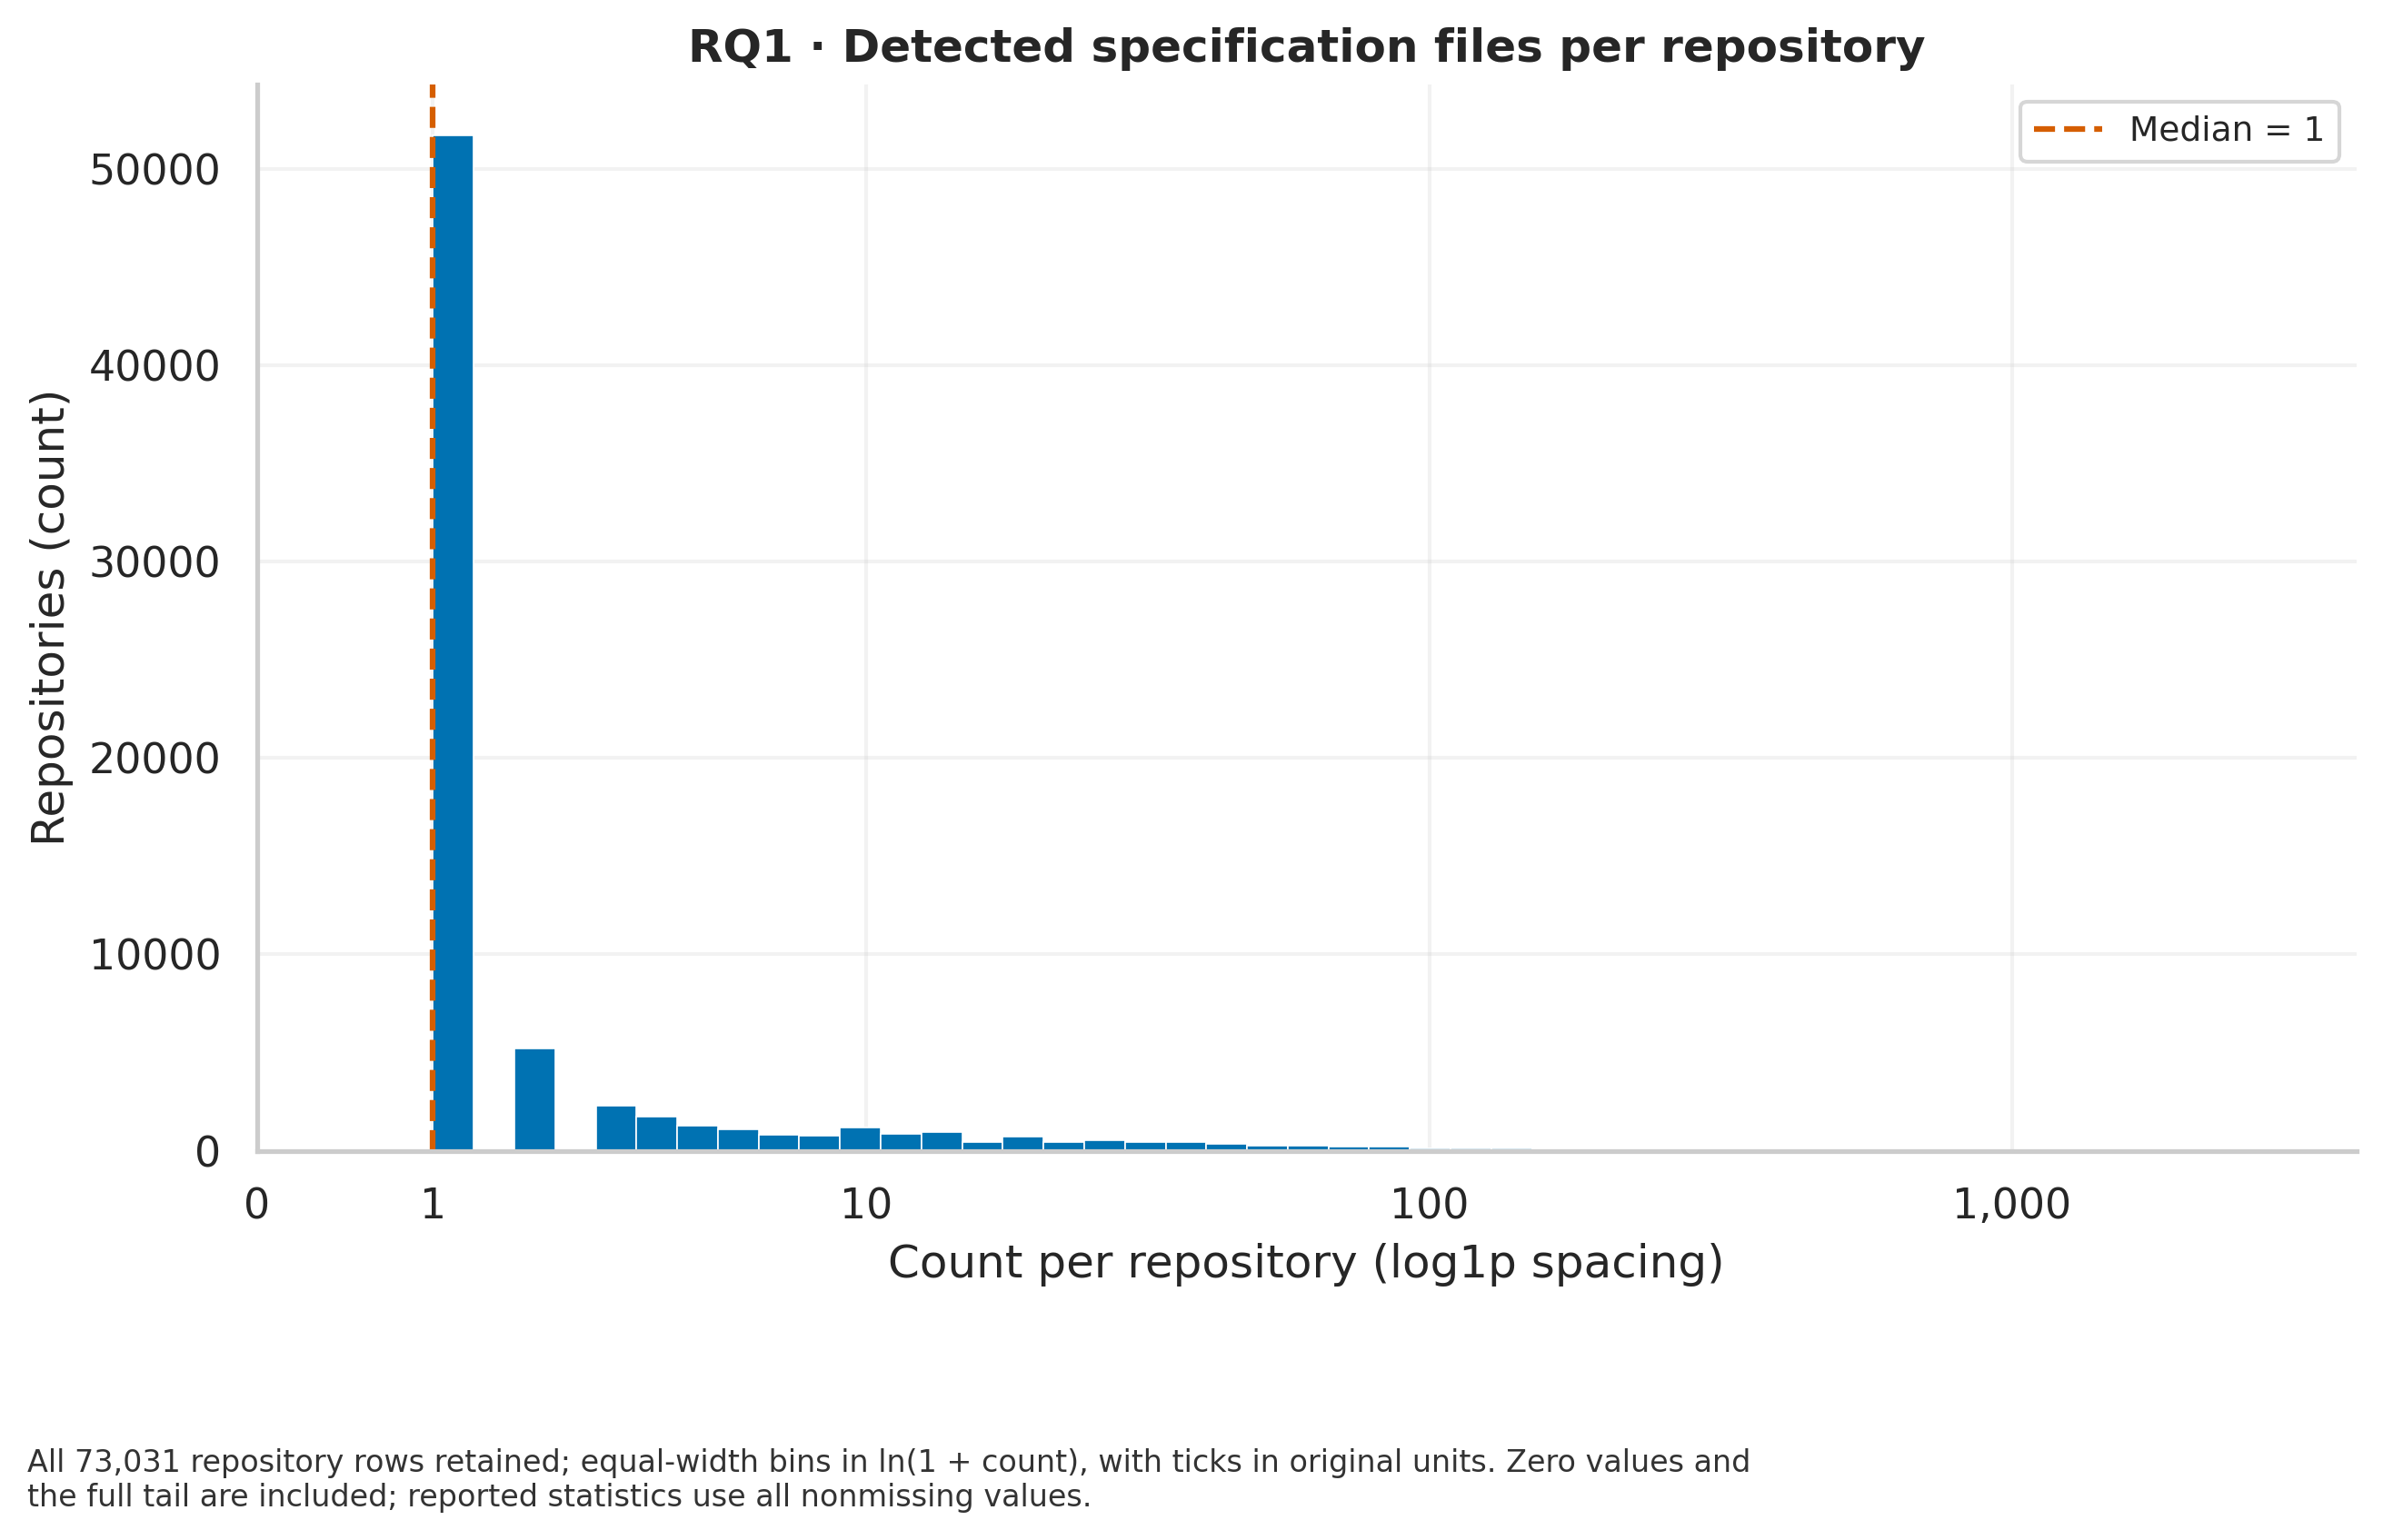

**Caption.** All 73,031 repository rows retained; equal-width bins in ln(1 + count), with ticks in original units. Zero values and the full tail are included; reported statistics use all nonmissing values.

**Interpretation.** RQ1 · Detected specification files per repository: median 1, mean 6.45, maximum 2,708 (n=73,031).

In [6]:
show(rp.specifications(r, OUT))

### Logged-in specification contributors

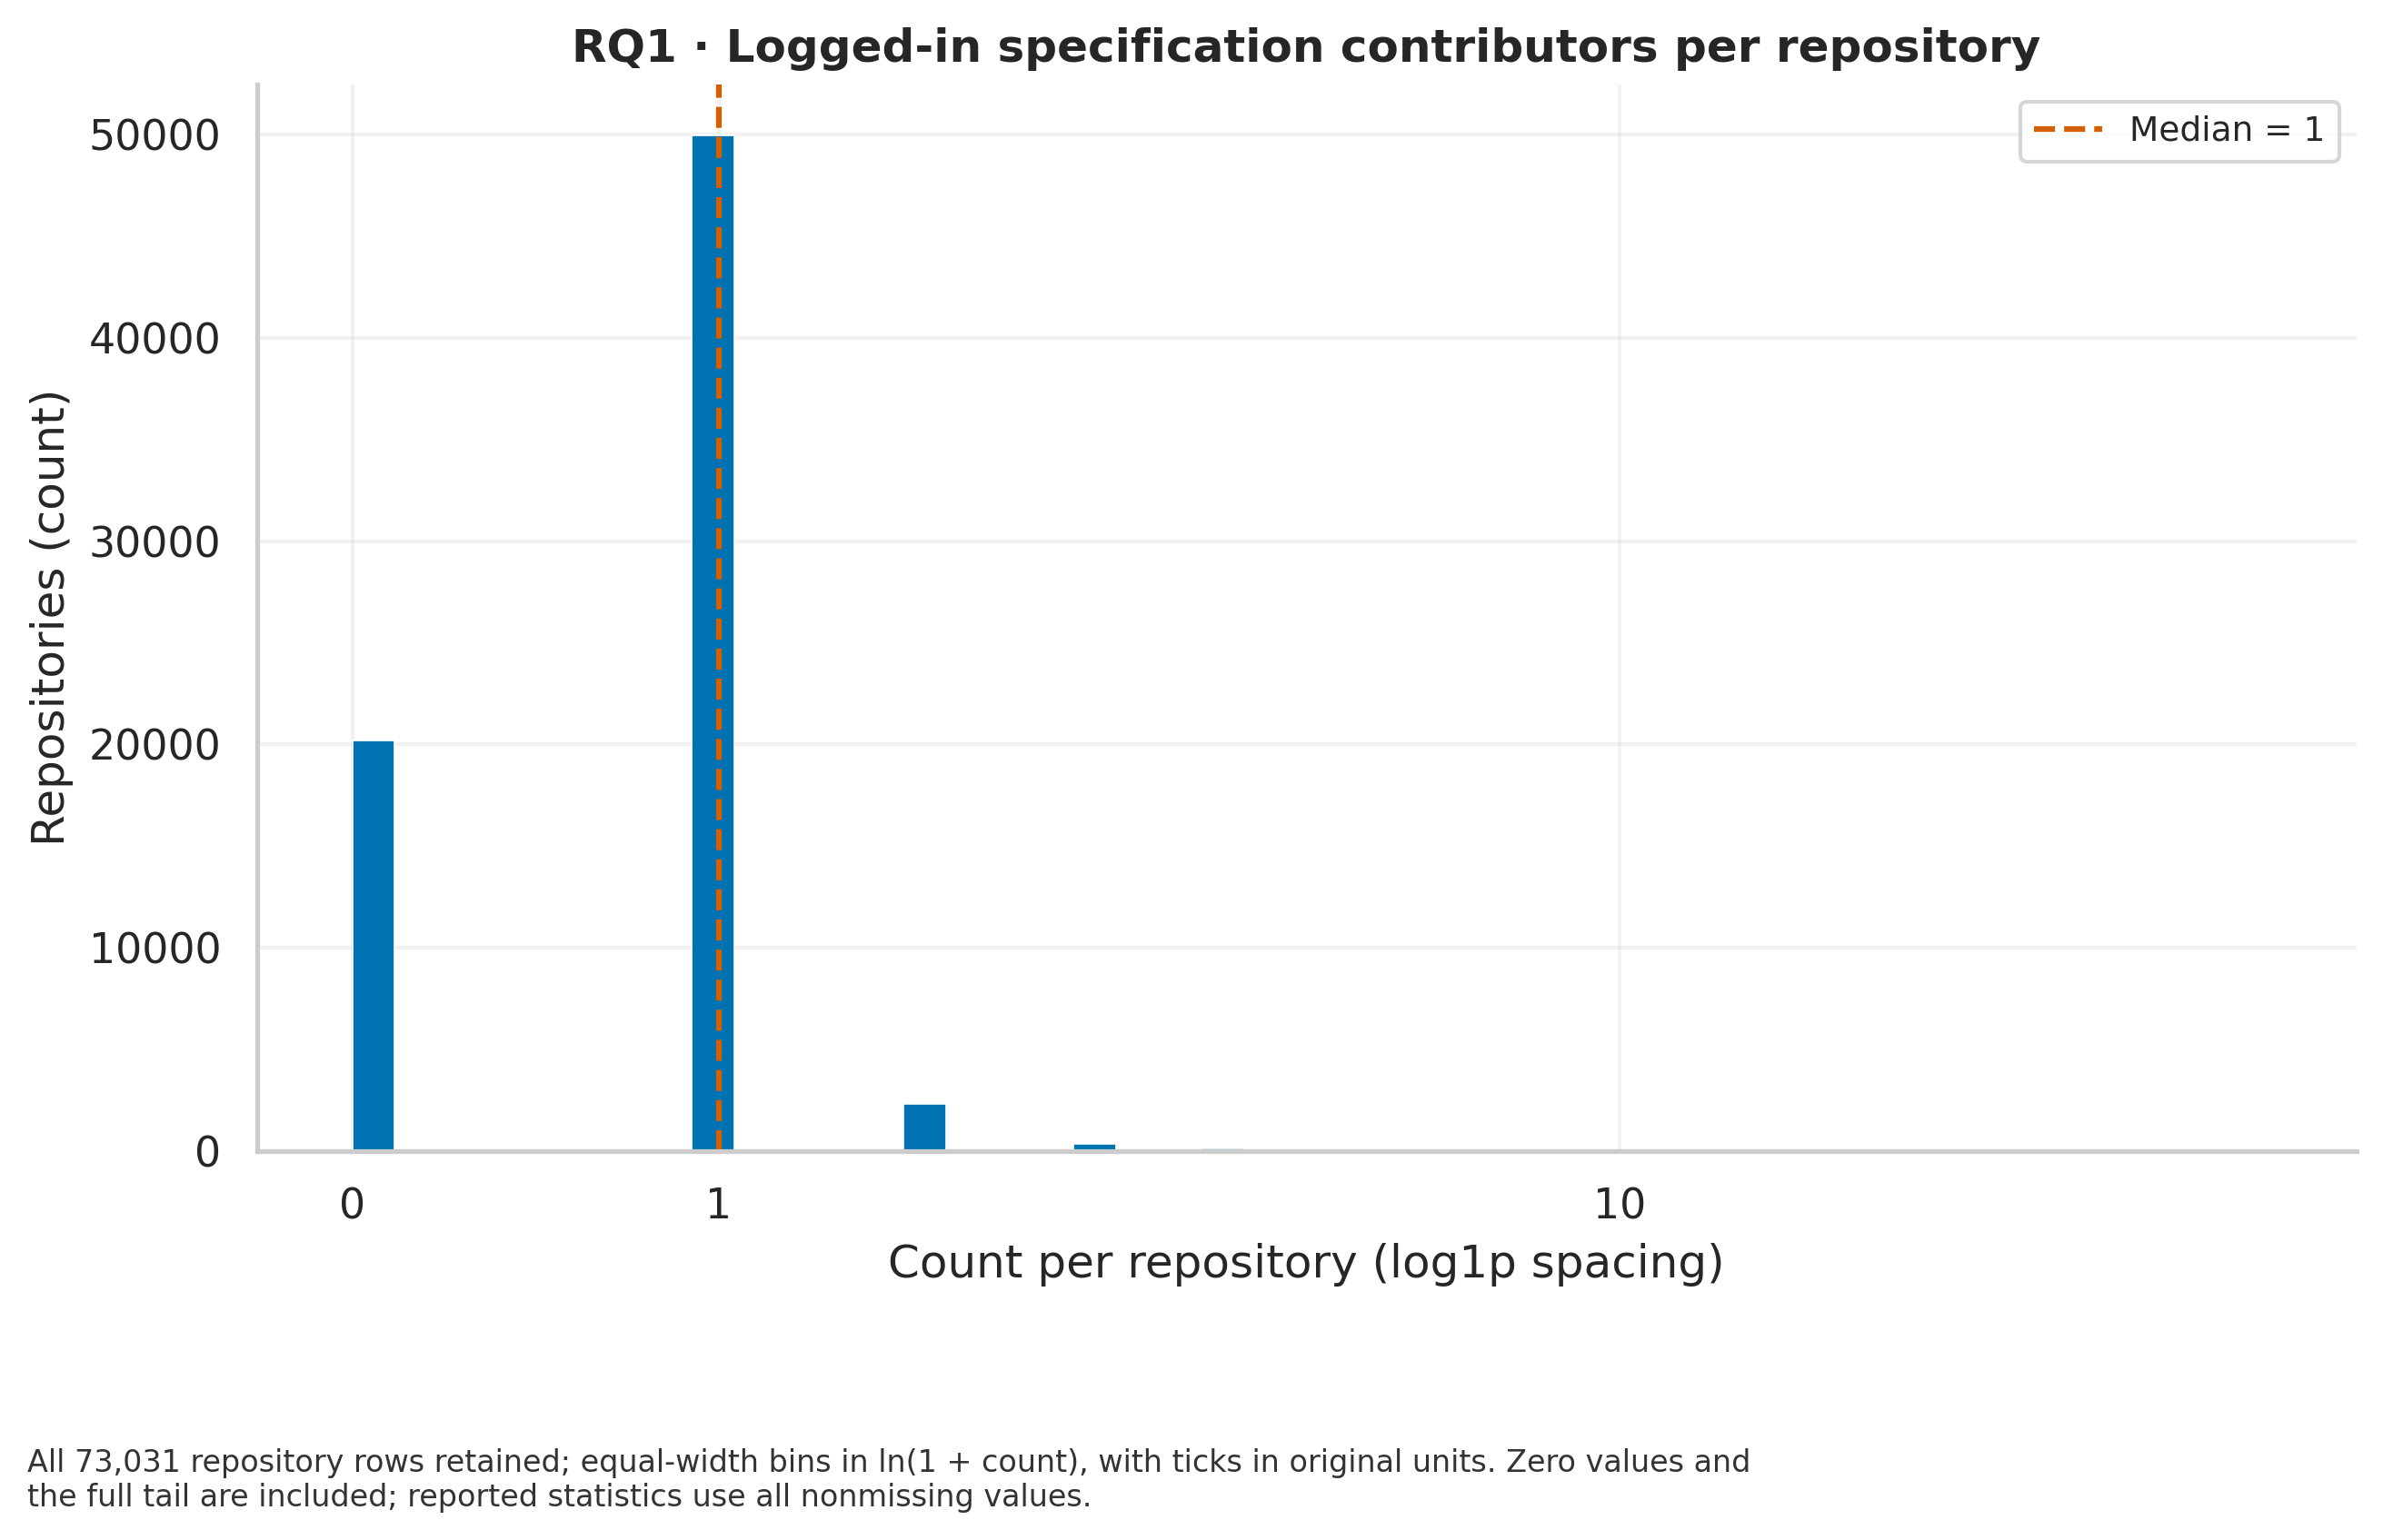

**Caption.** All 73,031 repository rows retained; equal-width bins in ln(1 + count), with ticks in original units. Zero values and the full tail are included; reported statistics use all nonmissing values.

**Interpretation.** RQ1 · Logged-in specification contributors per repository: median 1, mean 0.78, maximum 36 (n=73,031). Counts cover unique GitHub accounts committing to detected specification files, not all repository contributors; zero does not establish no human activity.

In [7]:
show(rp.contributors(r, OUT))

## RQ2: At what repository age is SDD first detected?

Repository ages use **only `adoption_age_status == 'valid'`**. Category ages independently use **only `tool_adoption_age_status == 'valid'`**. No global filtering is applied. Raw negative ages and rounded `-0.0` cannot override status. Plots disclose total inclusions/exclusions and show valid group sizes. Group tables also report excluded statuses per group. IQRs describe distributions, not confidence intervals.

In [8]:
display(tables['age_status_audit'])
display(tables['numeric_summary'].query("grain.str.contains('valid ages')", engine='python'))

,grain,status,records,included_in_age_analysis
0,repository,valid,57164,True
1,repository,predates_repo_creation,15680,False
2,repository,missing_date,187,False
3,repository-category,valid,59617,True
4,repository-category,predates_repo_creation,16051,False
5,repository-category,missing_date,198,False


,grain,variable,n_non_null,n_missing,median,mean,q25,q75,maximum
5,repository: valid ages,adoption_age_days,57164,0,0.13,113.122799,0.0,17.00,6459.79
6,repository: valid ages,adoption_age_years,57164,0,0.00,0.309573,0.0,0.05,17.69
8,repository-category: valid ages,tool_adoption_age_days,59617,0,0.19,114.234040,0.0,19.85,6459.79
9,repository-category: valid ages,tool_adoption_age_years,59617,0,0.00,0.312617,0.0,0.05,17.69


### Valid repository adoption-age distribution

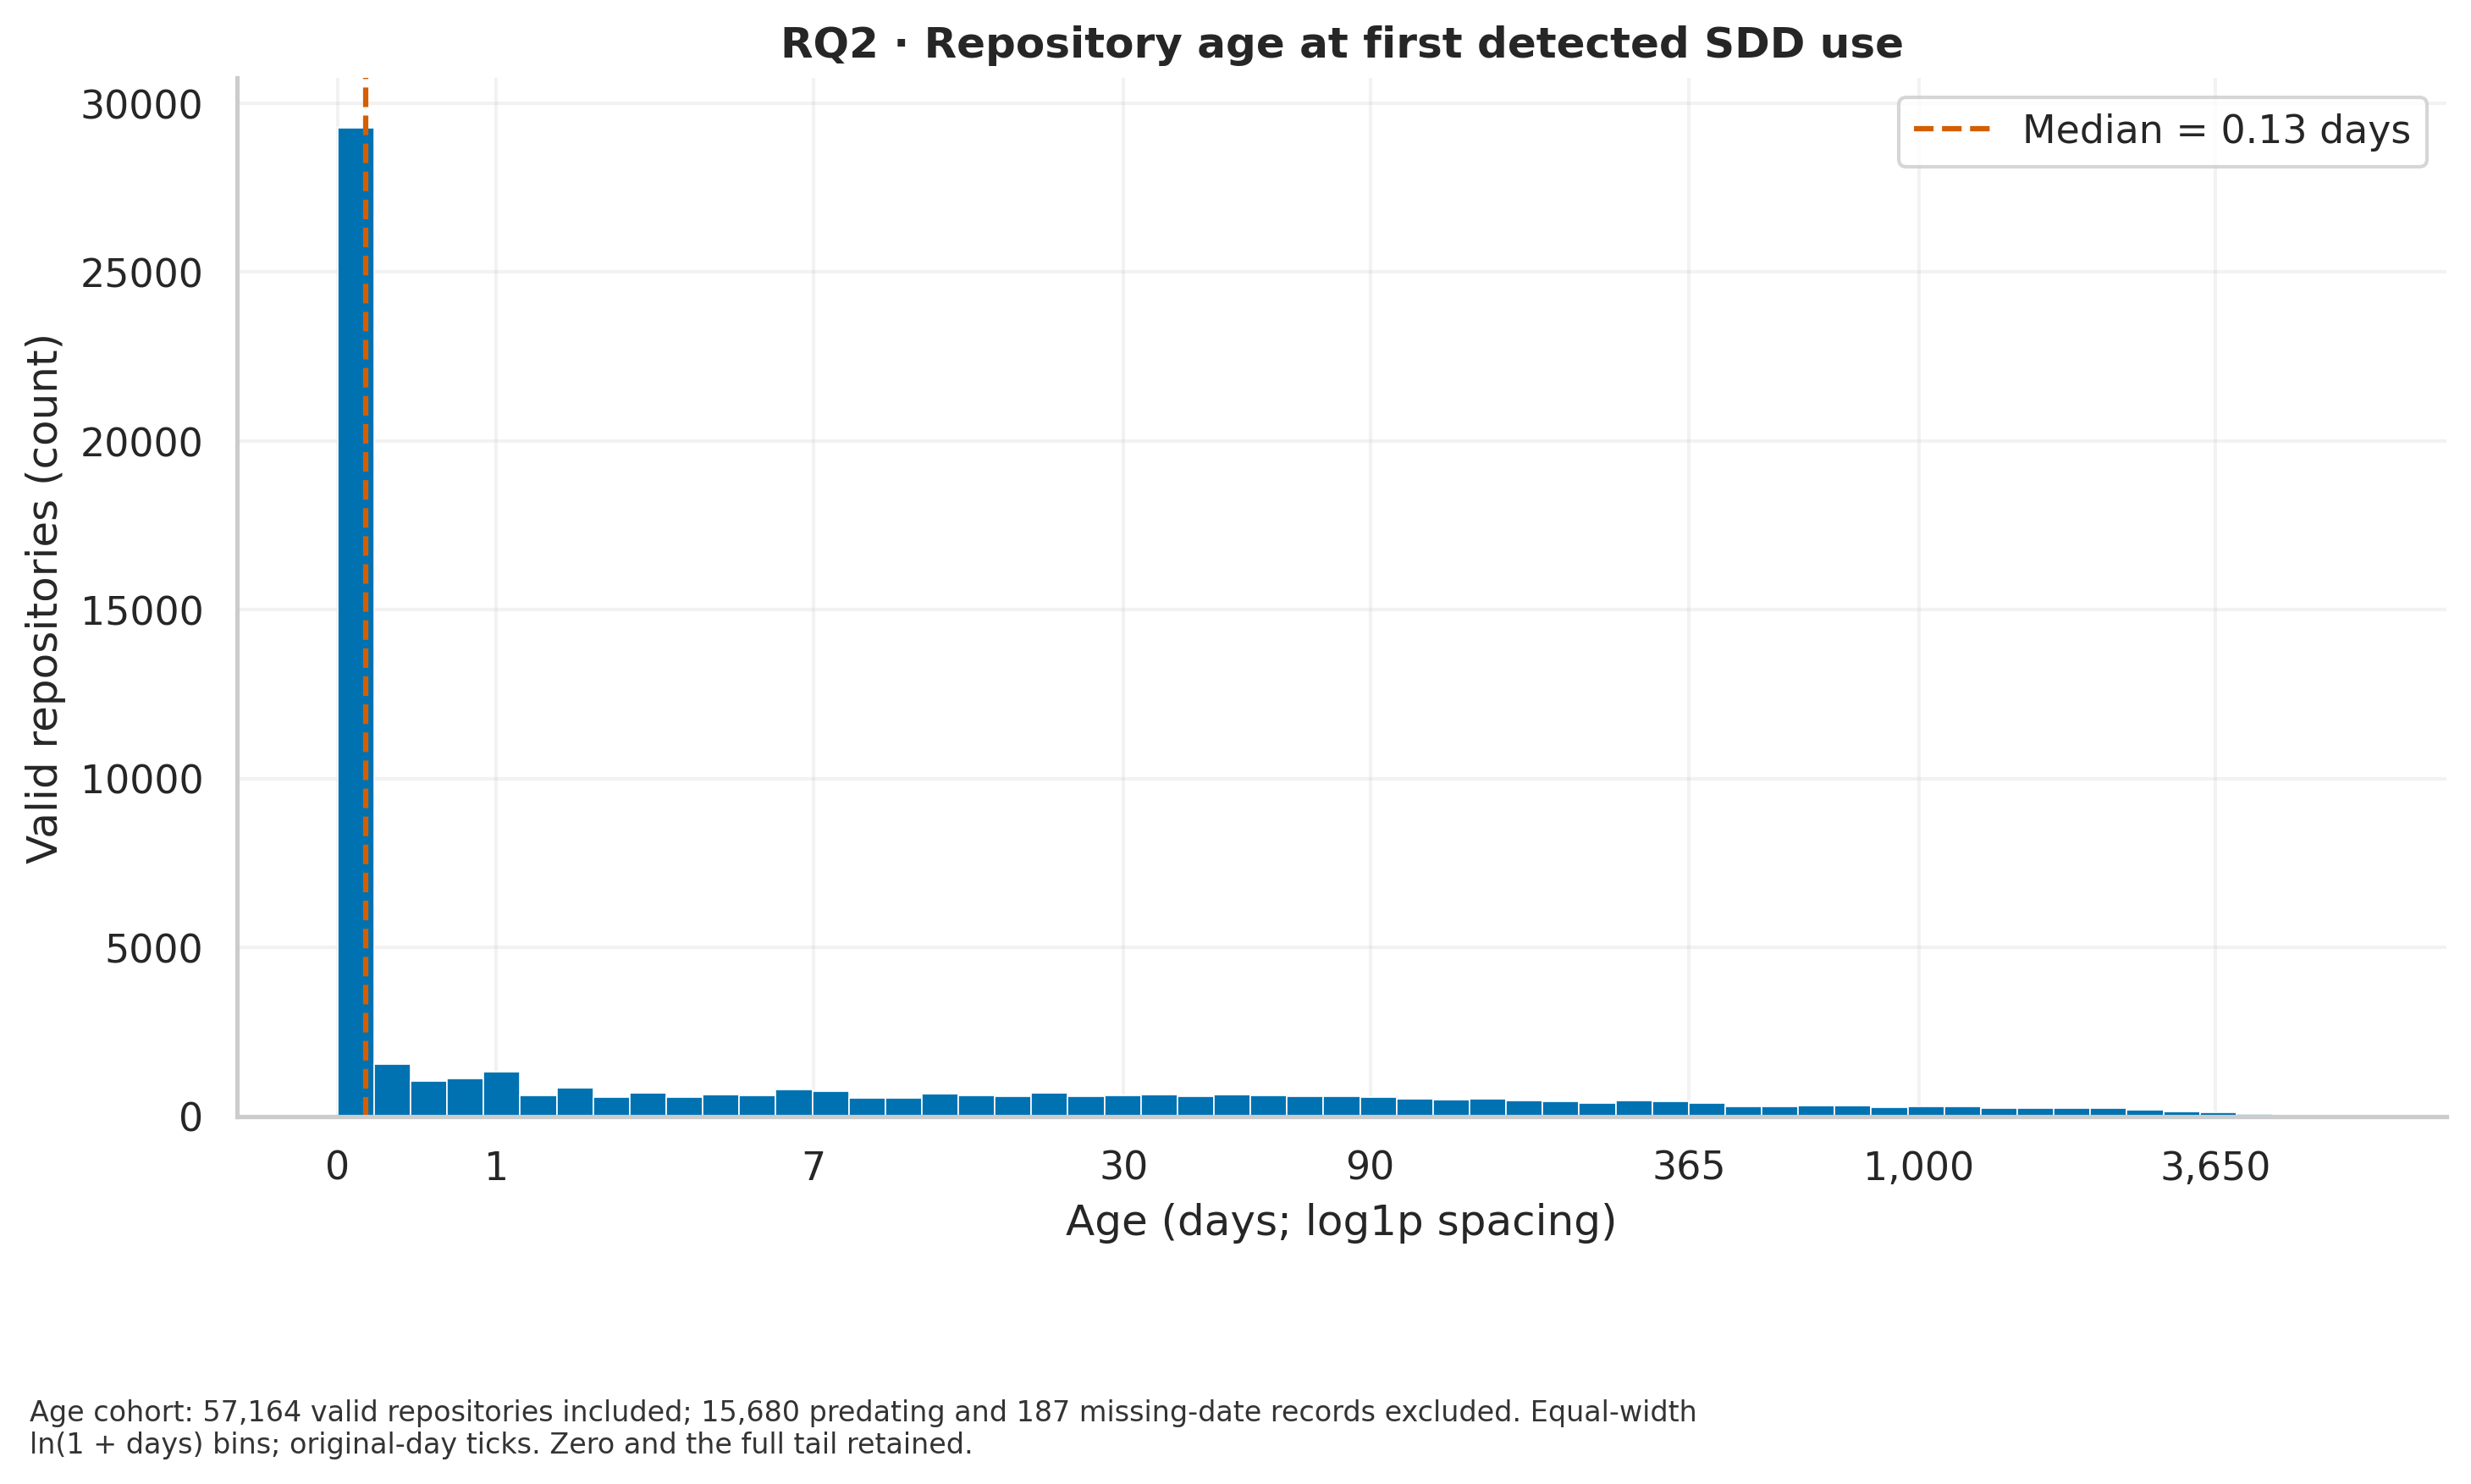

**Caption.** Age cohort: 57,164 valid repositories included; 15,680 predating and 187 missing-date records excluded. Equal-width ln(1 + days) bins; original-day ticks. Zero and the full tail retained.

**Interpretation.** Among valid ages, the median is 0.13 days and the middle 50% spans 0.00–17.00 days. The mean is 113.12 days; 58.7% of valid records have rounded ages of at most one day. This is conditional on valid chronology.

In [9]:
show(rp.adoption_age_distribution(r, OUT))

### Adoption age by owner type

,owner_type,n_non_null,median,mean,q25,q75,maximum,total_records,included_valid,excluded_predates_repo_creation,excluded_missing_date
0,Organization,20109,0.00,105.110418,0.00,0.63,6039.66,21370,20109,1237,24
1,User,37055,1.09,117.470957,0.02,29.95,6459.79,51661,37055,14443,163


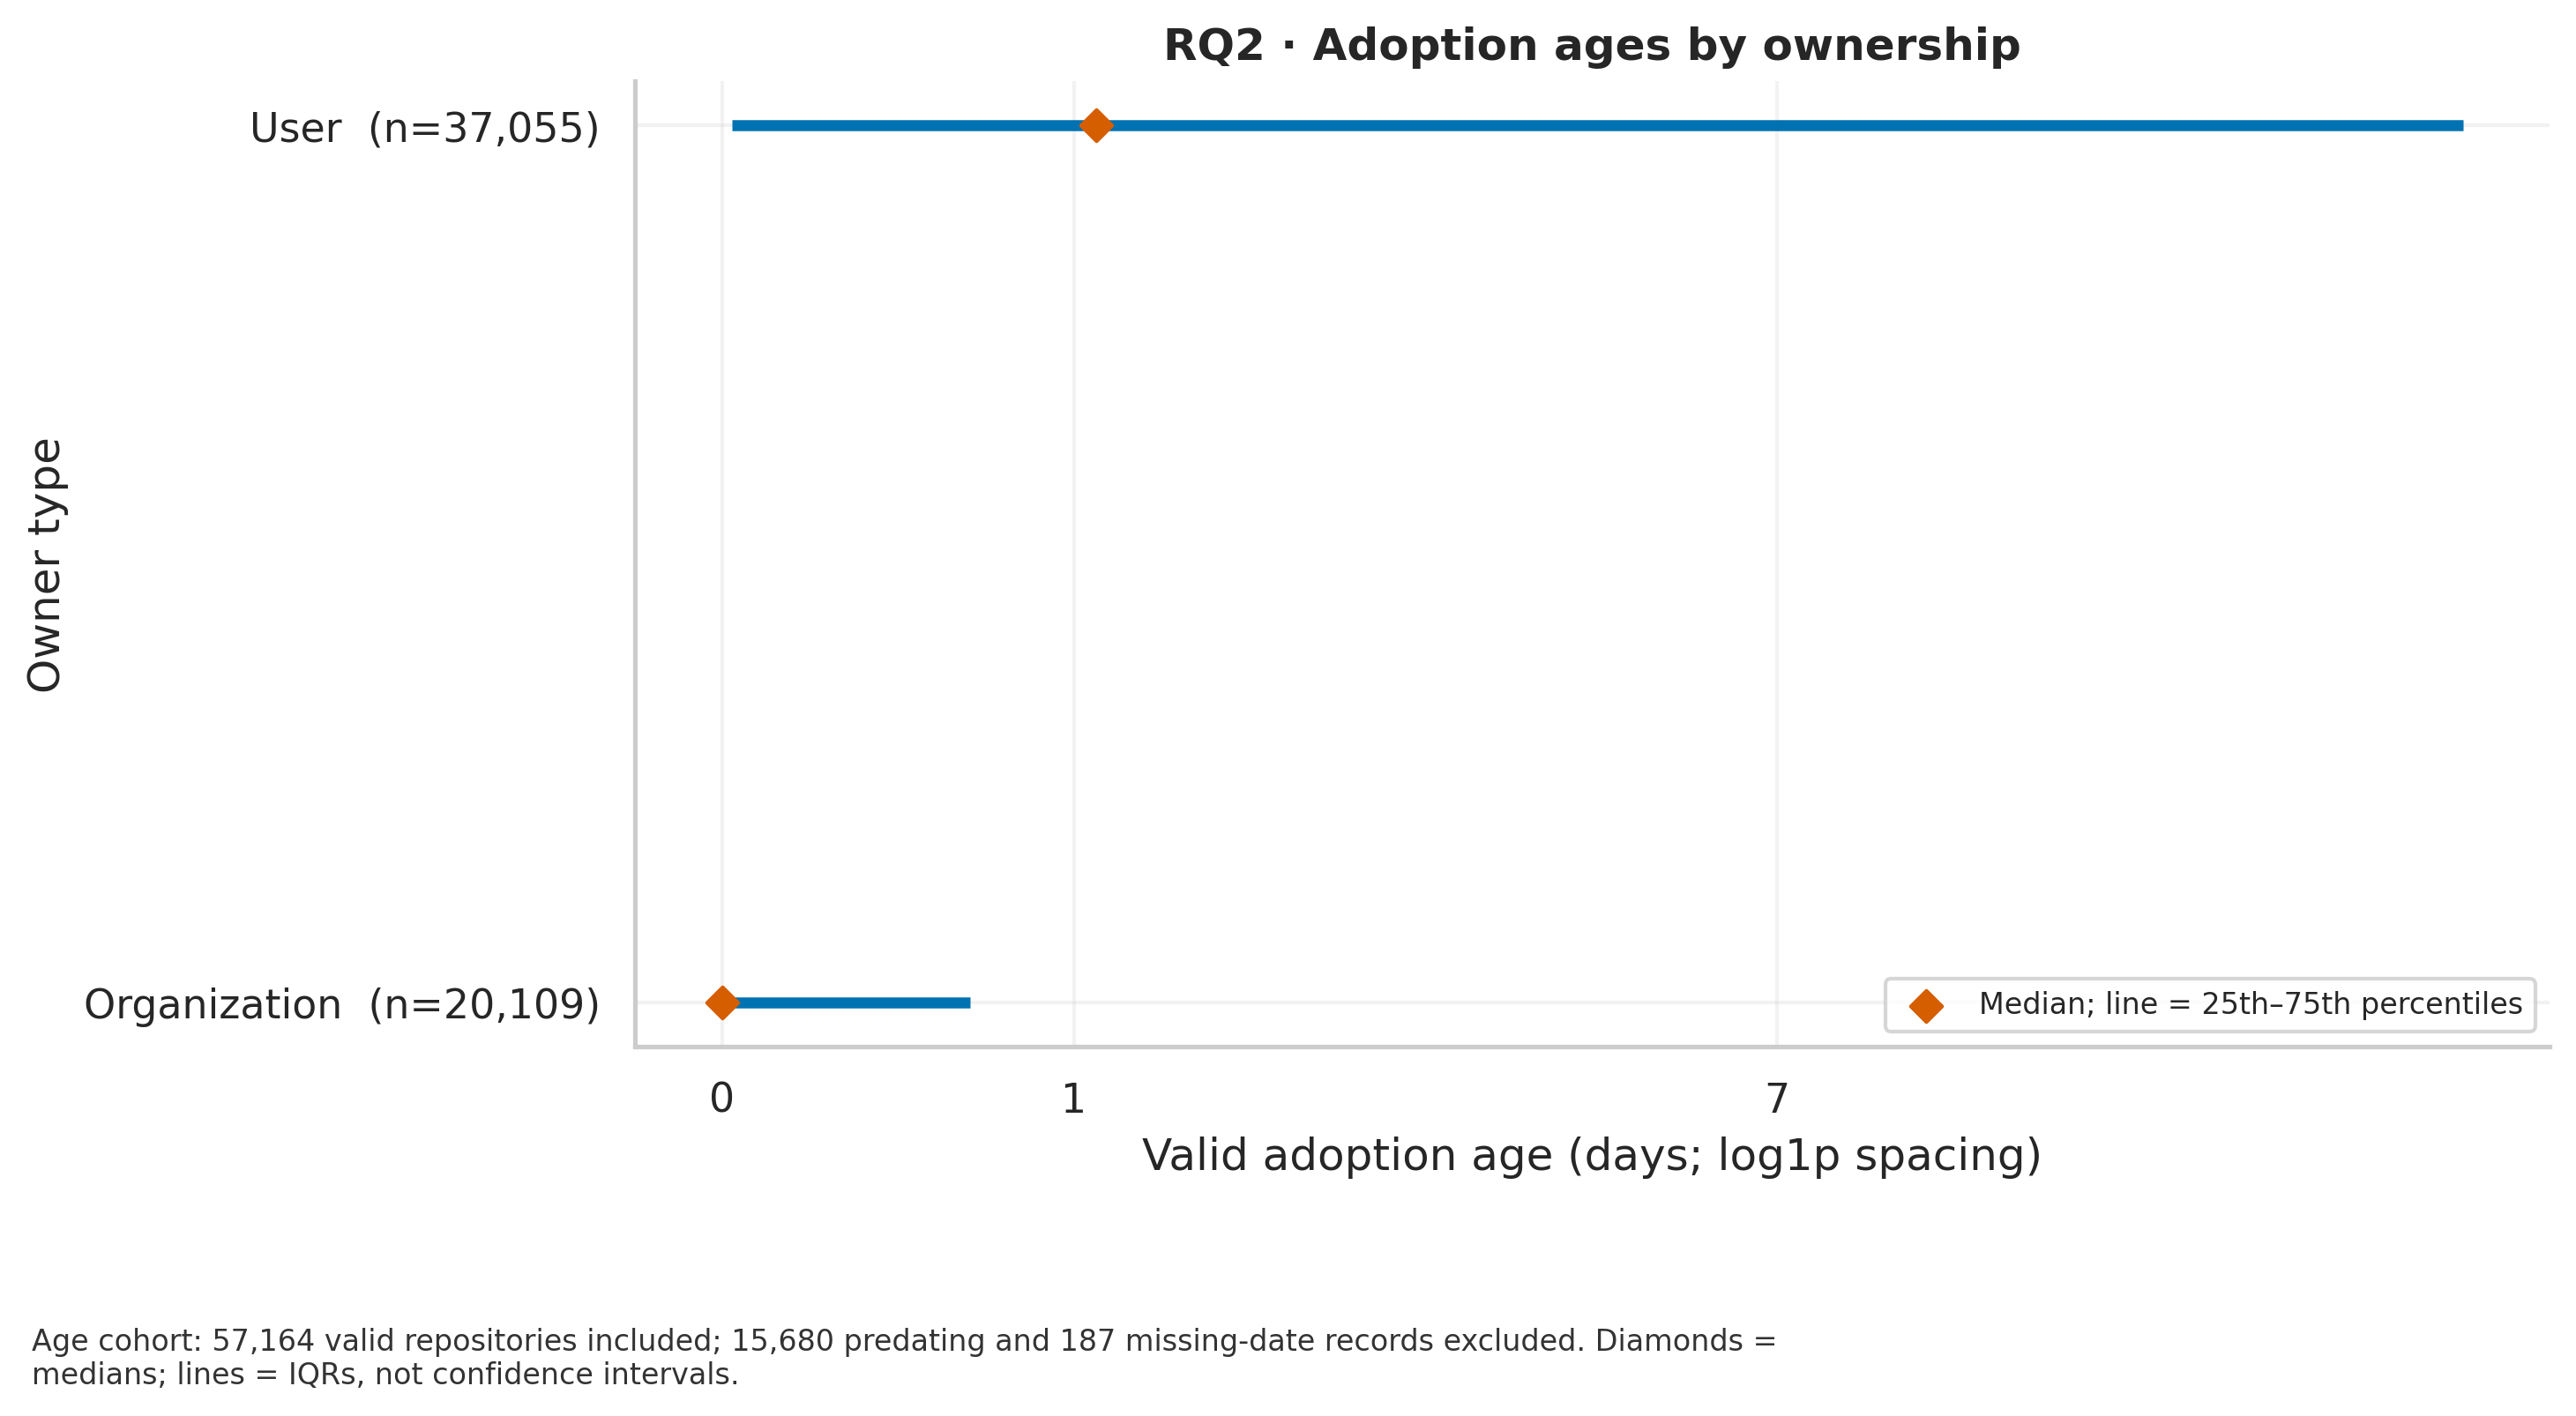

**Caption.** Age cohort: 57,164 valid repositories included; 15,680 predating and 187 missing-date records excluded. Diamonds = medians; lines = IQRs, not confidence intervals.

**Interpretation.** Organization: median 0.00 days (valid n=20,109); User: median 1.09 days (valid n=37,055). Differences are descriptive and do not establish causation.

In [10]:
display(tables['age_by_ownership'])
show(rp.age_groups(r, OUT))

### Adoption age for common programming languages

,repo_language,n_non_null,median,mean,q25,q75,maximum,total_records,included_valid,excluded_predates_repo_creation,excluded_missing_date
0,1C Enterprise,2,44.160,44.16000,25.9750,62.3450,80.53,2,2,0,0
1,ABAP,1,50.490,50.49000,50.4900,50.4900,50.49,1,1,0,0
2,APL,1,3.020,3.02000,3.0200,3.0200,3.02,1,1,0,0
3,ASL,2,0.000,0.00000,0.0000,0.0000,0.00,2,2,0,0
4,ActionScript,1,0.390,0.39000,0.3900,0.3900,0.39,2,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...
194,Zig,61,3.610,95.20623,0.1200,78.6400,933.50,96,61,35,0
195,hoon,1,0.010,0.01000,0.0100,0.0100,0.01,1,1,0,0
196,mcfunction,1,45.110,45.11000,45.1100,45.1100,45.11,1,1,0,0
197,nesC,2,414.925,414.92500,412.0175,417.8325,420.74,2,2,0,0


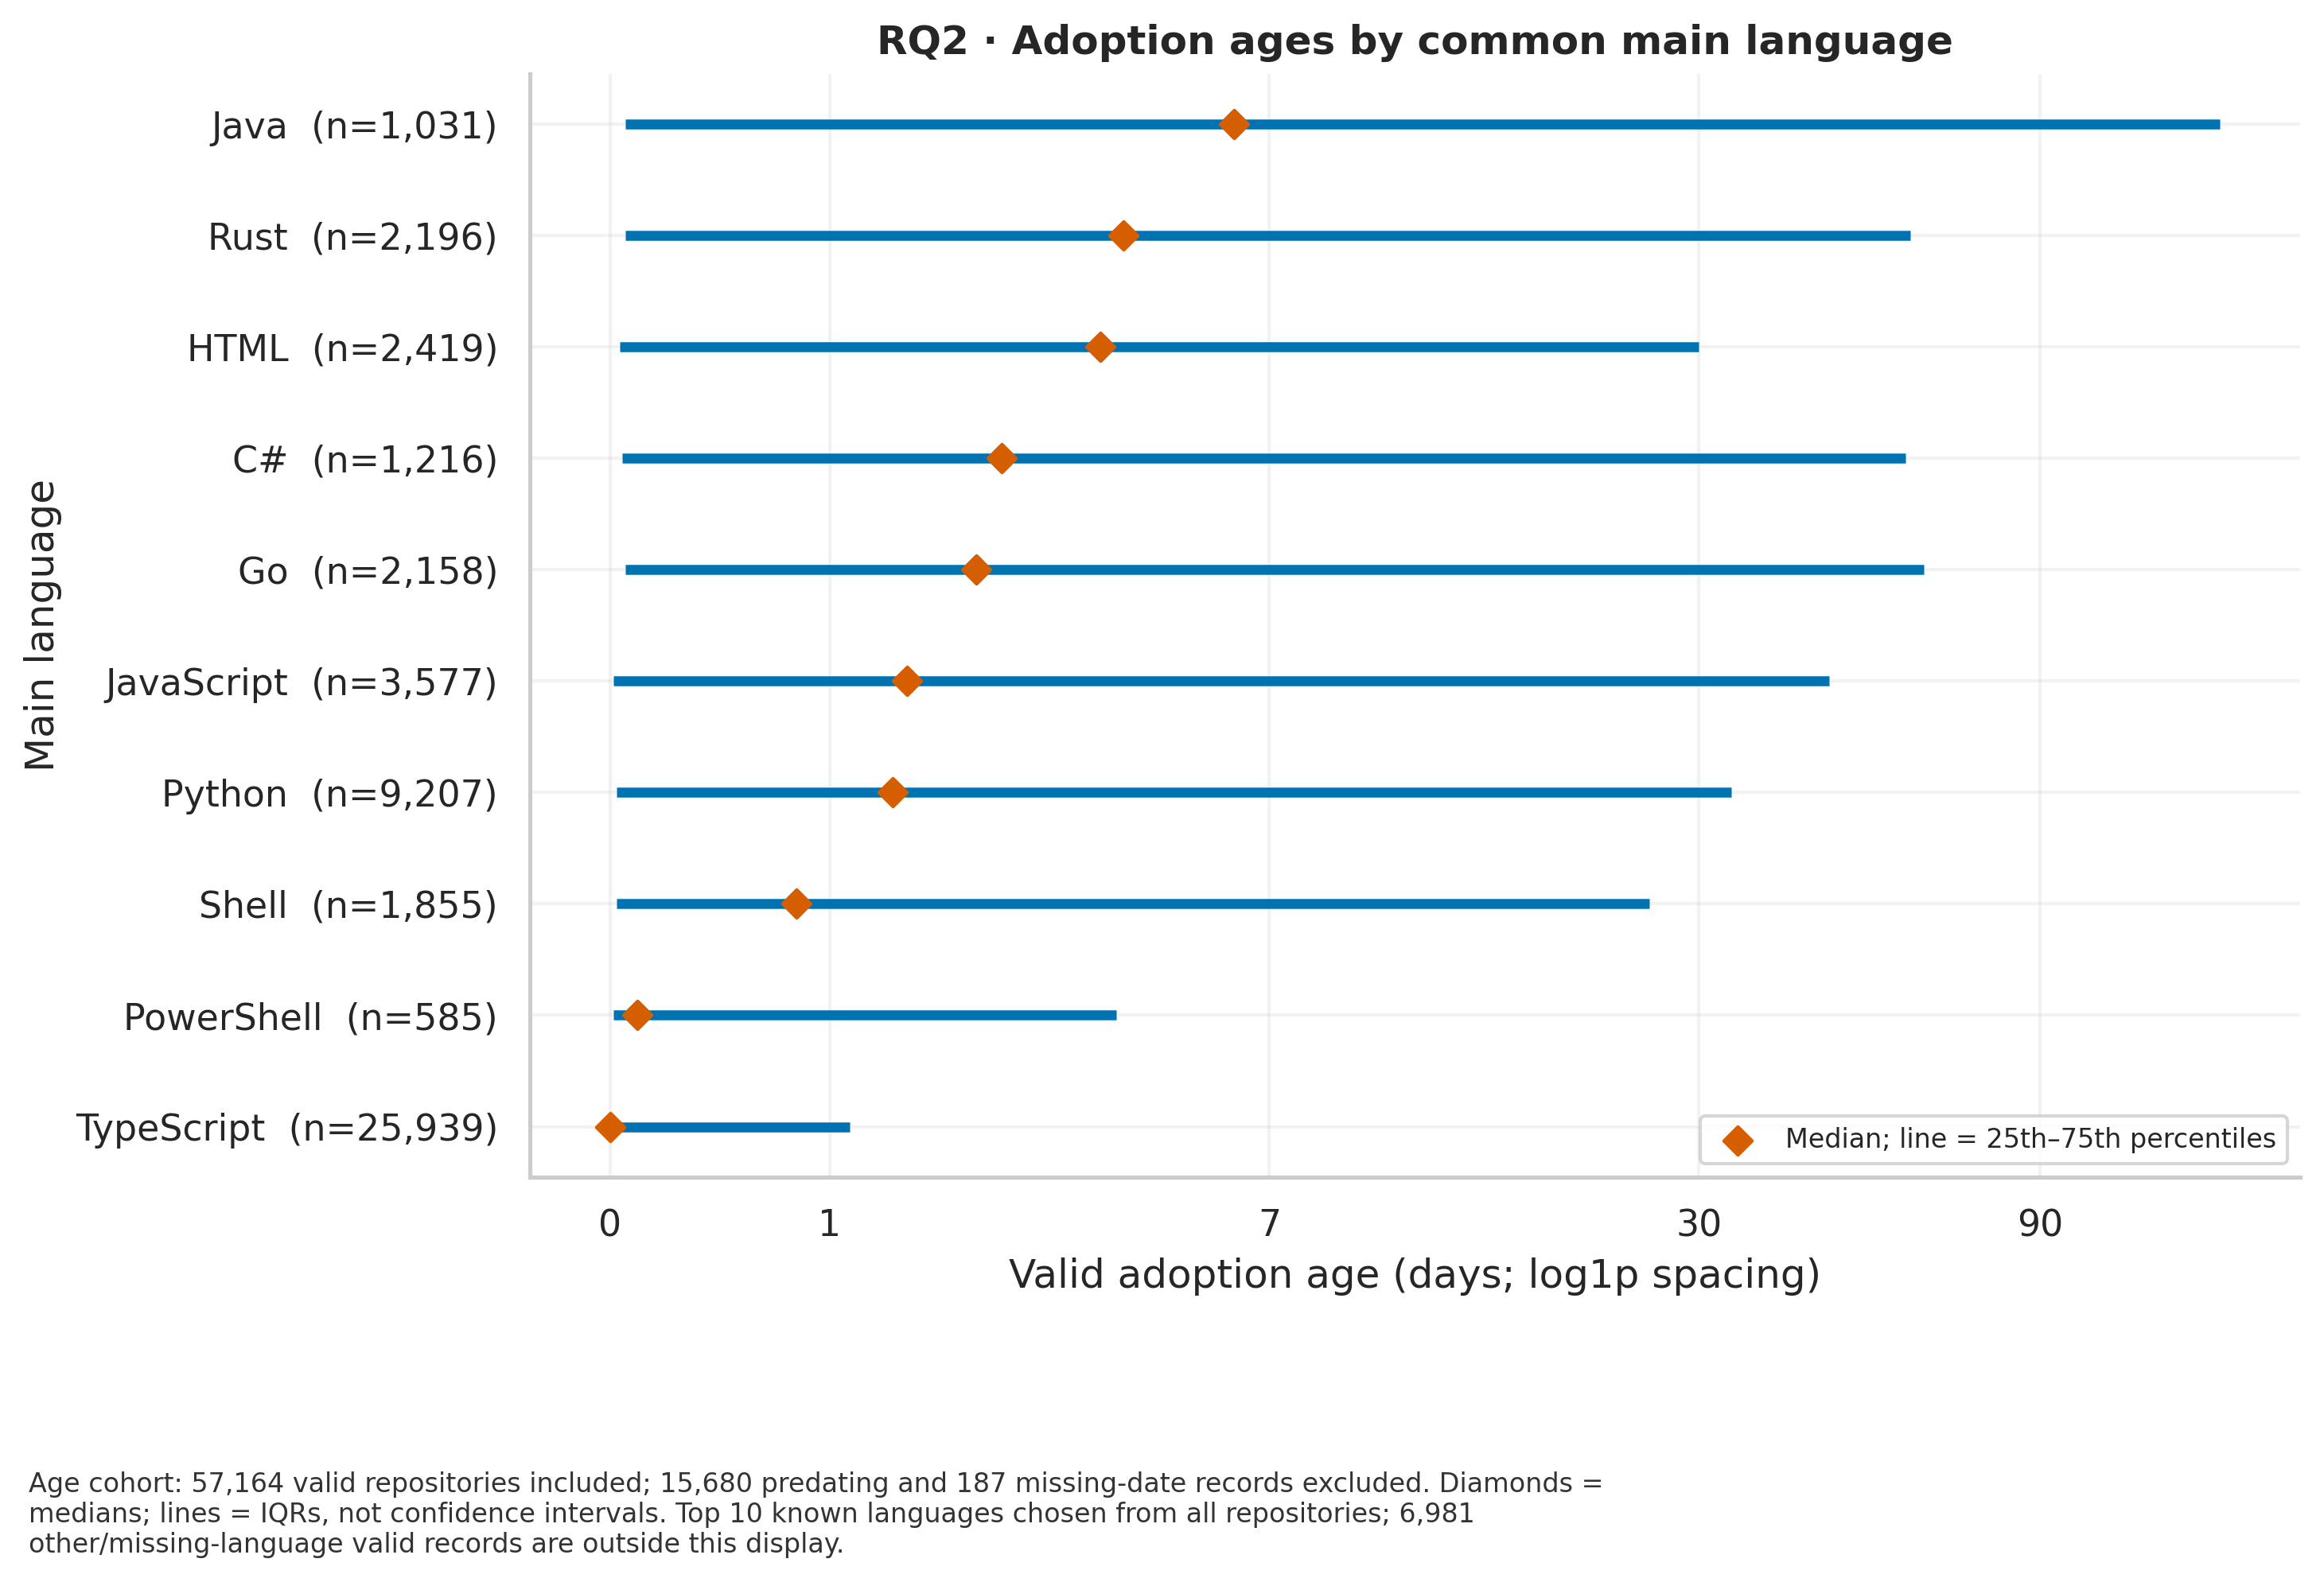

**Caption.** Age cohort: 57,164 valid repositories included; 15,680 predating and 187 missing-date records excluded. Diamonds = medians; lines = IQRs, not confidence intervals. Top 10 known languages chosen from all repositories; 6,981 other/missing-language valid records are outside this display.

**Interpretation.** TypeScript: median 0.00 days (valid n=25,939); PowerShell: median 0.09 days (valid n=585); Shell: median 0.80 days (valid n=1,855); Python: median 1.44 days (valid n=9,207); JavaScript: median 1.55 days (valid n=3,577); Go: median 2.17 days (valid n=2,158); C#: median 2.44 days (valid n=1,216); HTML: median 3.69 days (valid n=2,419); Rust: median 4.05 days (valid n=2,196); Java: median 6.16 days (valid n=1,031). Differences are descriptive and do not establish causation.

In [11]:
display(tables['age_by_language'])
show(rp.age_groups(r, OUT, 'repo_language'))

### Optional: category-specific adoption ages

,spec_tool,n_non_null,median,mean,q25,q75,maximum,total_records,included_valid,excluded_predates_repo_creation,excluded_missing_date
0,adhoc_other,8366,8.920,189.532955,0.1200,76.7550,6459.79,10239,8366,1835,38
1,agent_os,174,6.740,139.766782,0.1900,103.4900,3867.22,237,174,63,0
2,caffeine,13738,0.000,0.201794,0.0000,0.0000,71.89,13749,13738,11,0
3,claude_code,673,10.690,196.353611,0.2900,107.1200,5196.45,833,673,160,0
4,codex,57,11.390,130.071404,0.2000,70.6000,3356.08,69,57,12,0
5,conductor,696,22.420,241.493103,1.4750,167.8625,5840.49,936,696,240,0
6,cursor,56,5.295,83.995536,0.0200,77.8175,799.71,65,56,9,0
7,docs_embedded,6399,1.920,128.492596,0.0300,36.9250,6218.78,8655,6399,2217,39
8,dot_specs,197,6.260,136.801472,0.1100,41.5800,2718.19,250,197,51,2
9,gsd,120,6.395,123.619750,0.1175,44.4350,3974.16,181,120,61,0


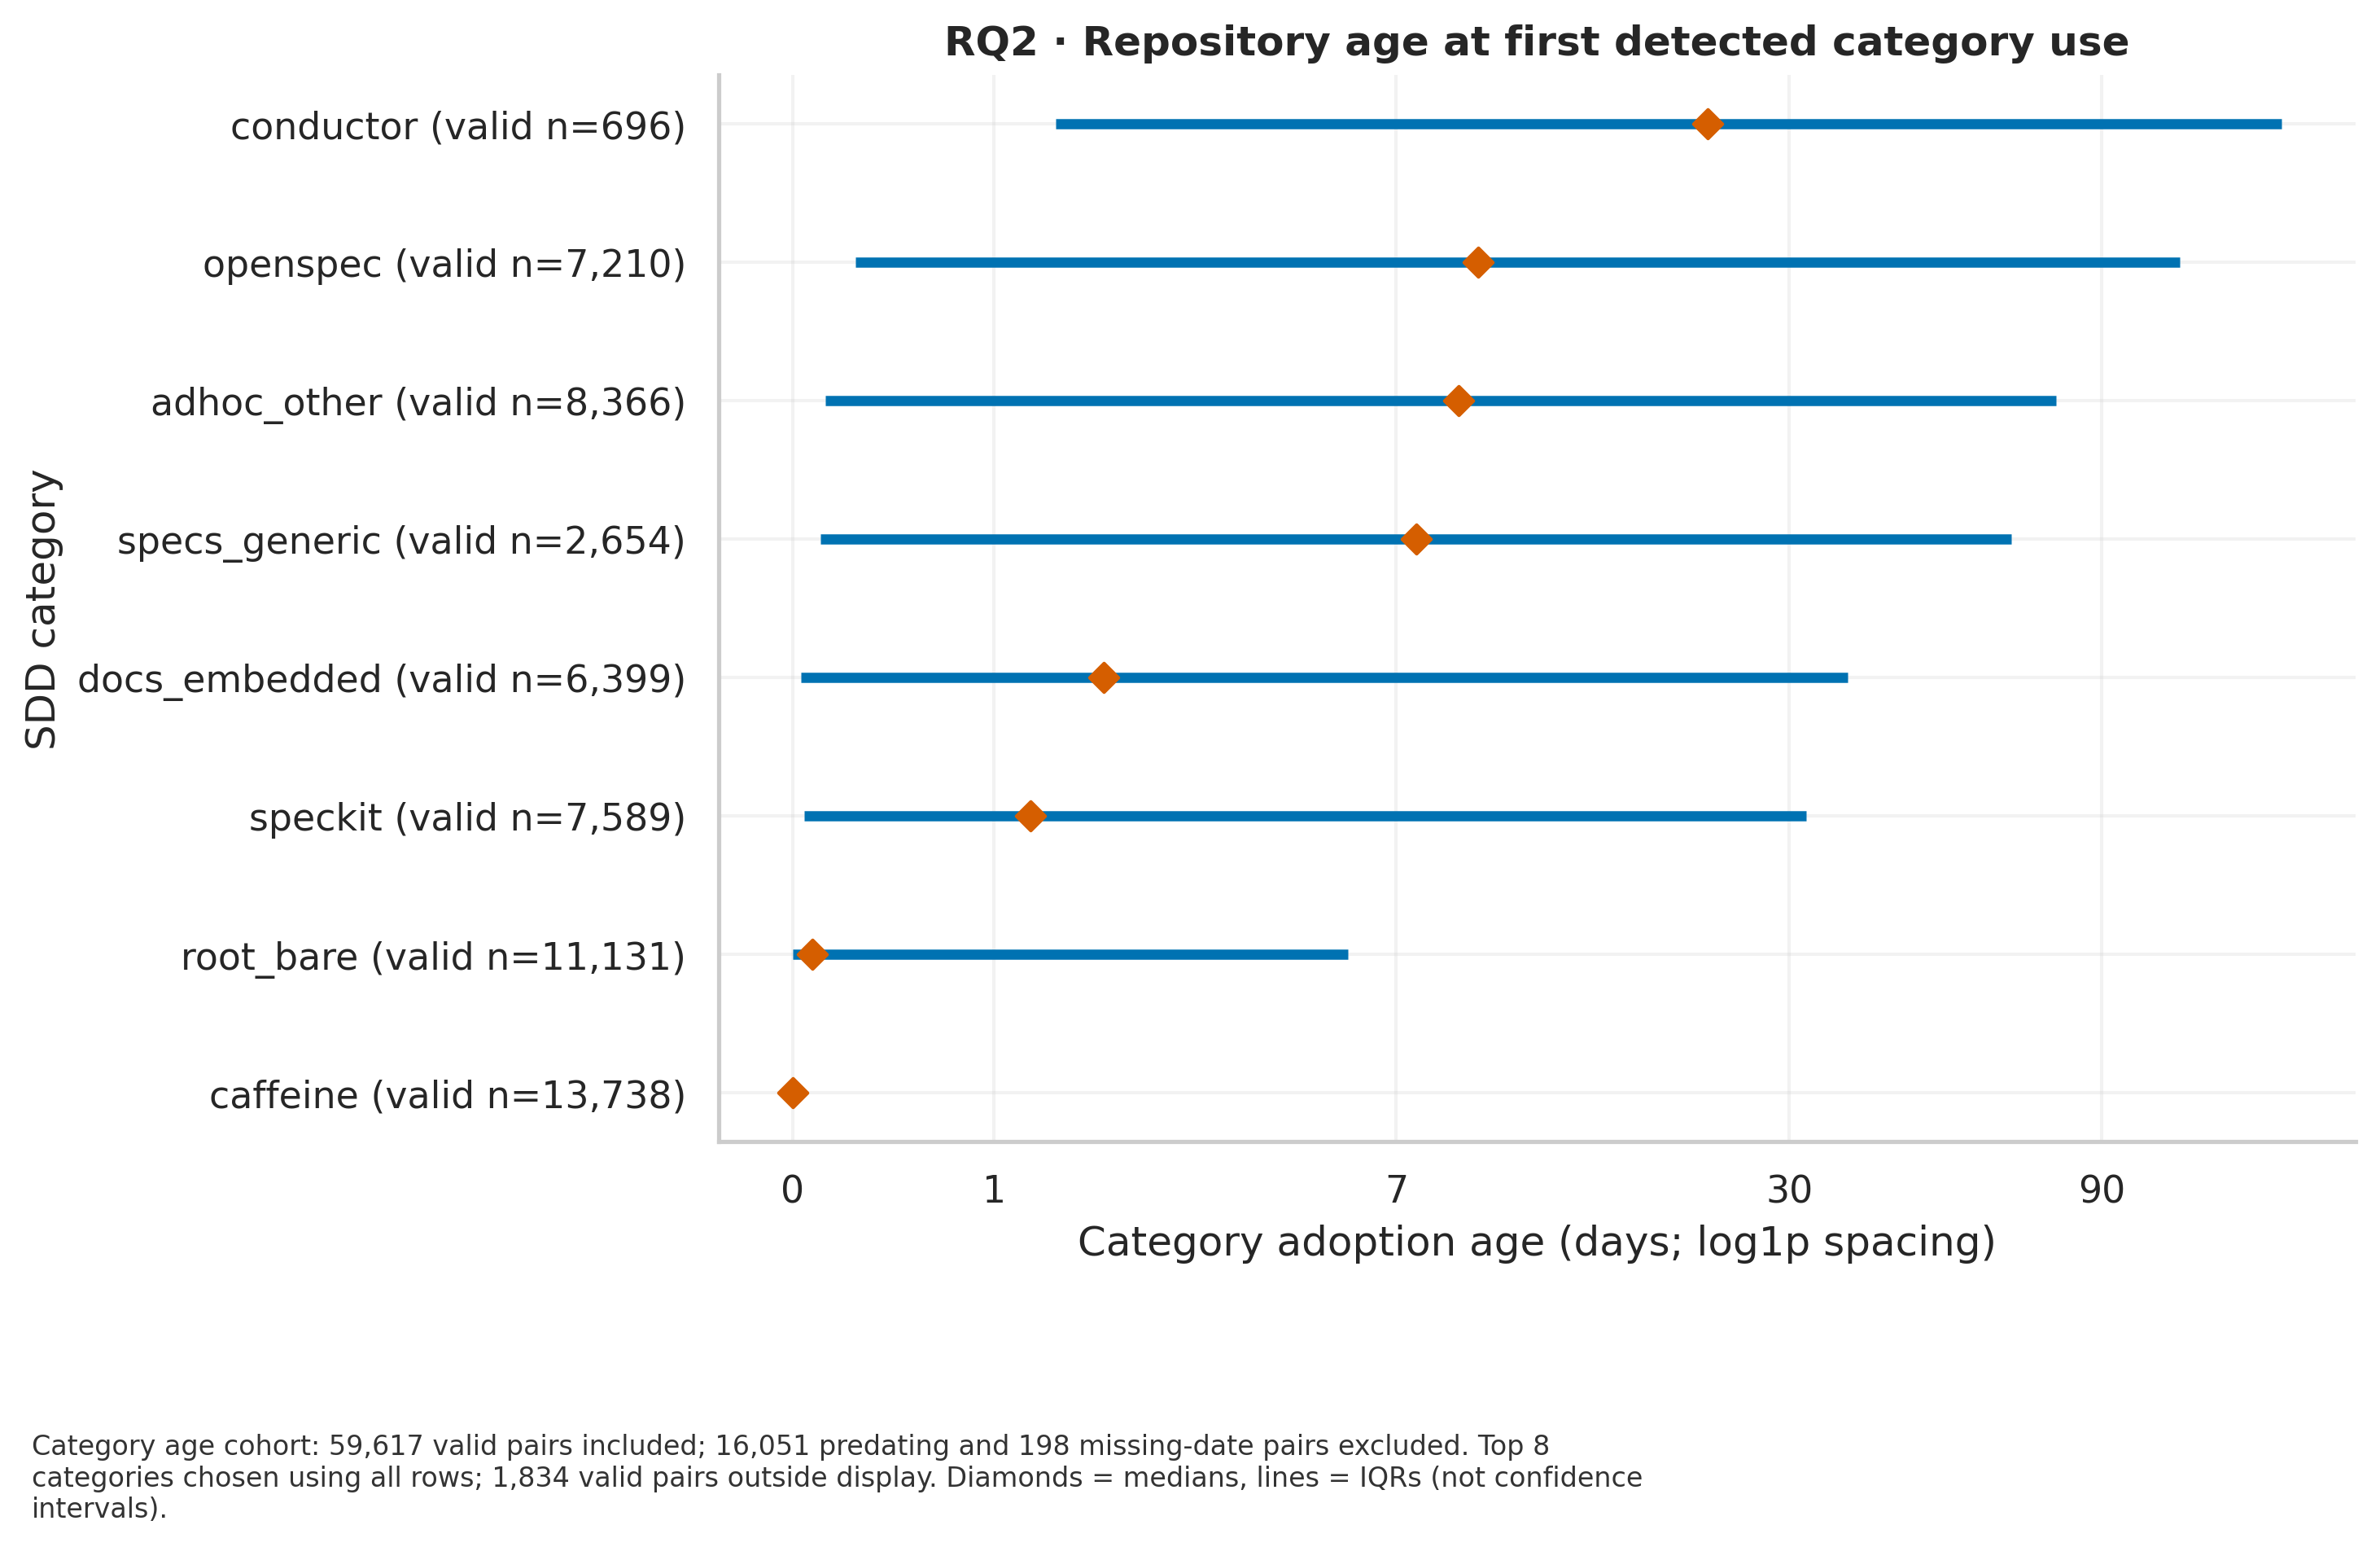

**Caption.** Category age cohort: 59,617 valid pairs included; 16,051 predating and 198 missing-date pairs excluded. Top 8 categories chosen using all rows; 1,834 valid pairs outside display. Diamonds = medians, lines = IQRs (not confidence intervals).

**Interpretation.** Category ages use tool_adoption_age_status, independently of repository-age status. Repositories may appear in multiple groups. caffeine: 0.00 days; root_bare: 0.07 days; speckit: 1.27 days; docs_embedded: 1.92 days; specs_generic: 7.58 days; adhoc_other: 8.92 days; openspec: 9.60 days; conductor: 22.42 days.

In [12]:
display(tables['age_by_category'])
show(tp.category_ages(t, OUT))

## RQ3: How have detected adoption and category use changed over time?

Repository trends use `first_sdd_at`/`adoption_year`; category trends use `first_tool_adoption_at`. Dated predating records remain included because time trends do not require valid repository ages. Missing first-detection dates cannot be assigned to a period. Each repository contributes once to the repository trend, and once per category to category trends. These are first detections, **not monthly active usage**. July 2026 and the 2026 calendar year are incomplete; the last observed commit is not a verified collection cutoff.

### Monthly repository first detections

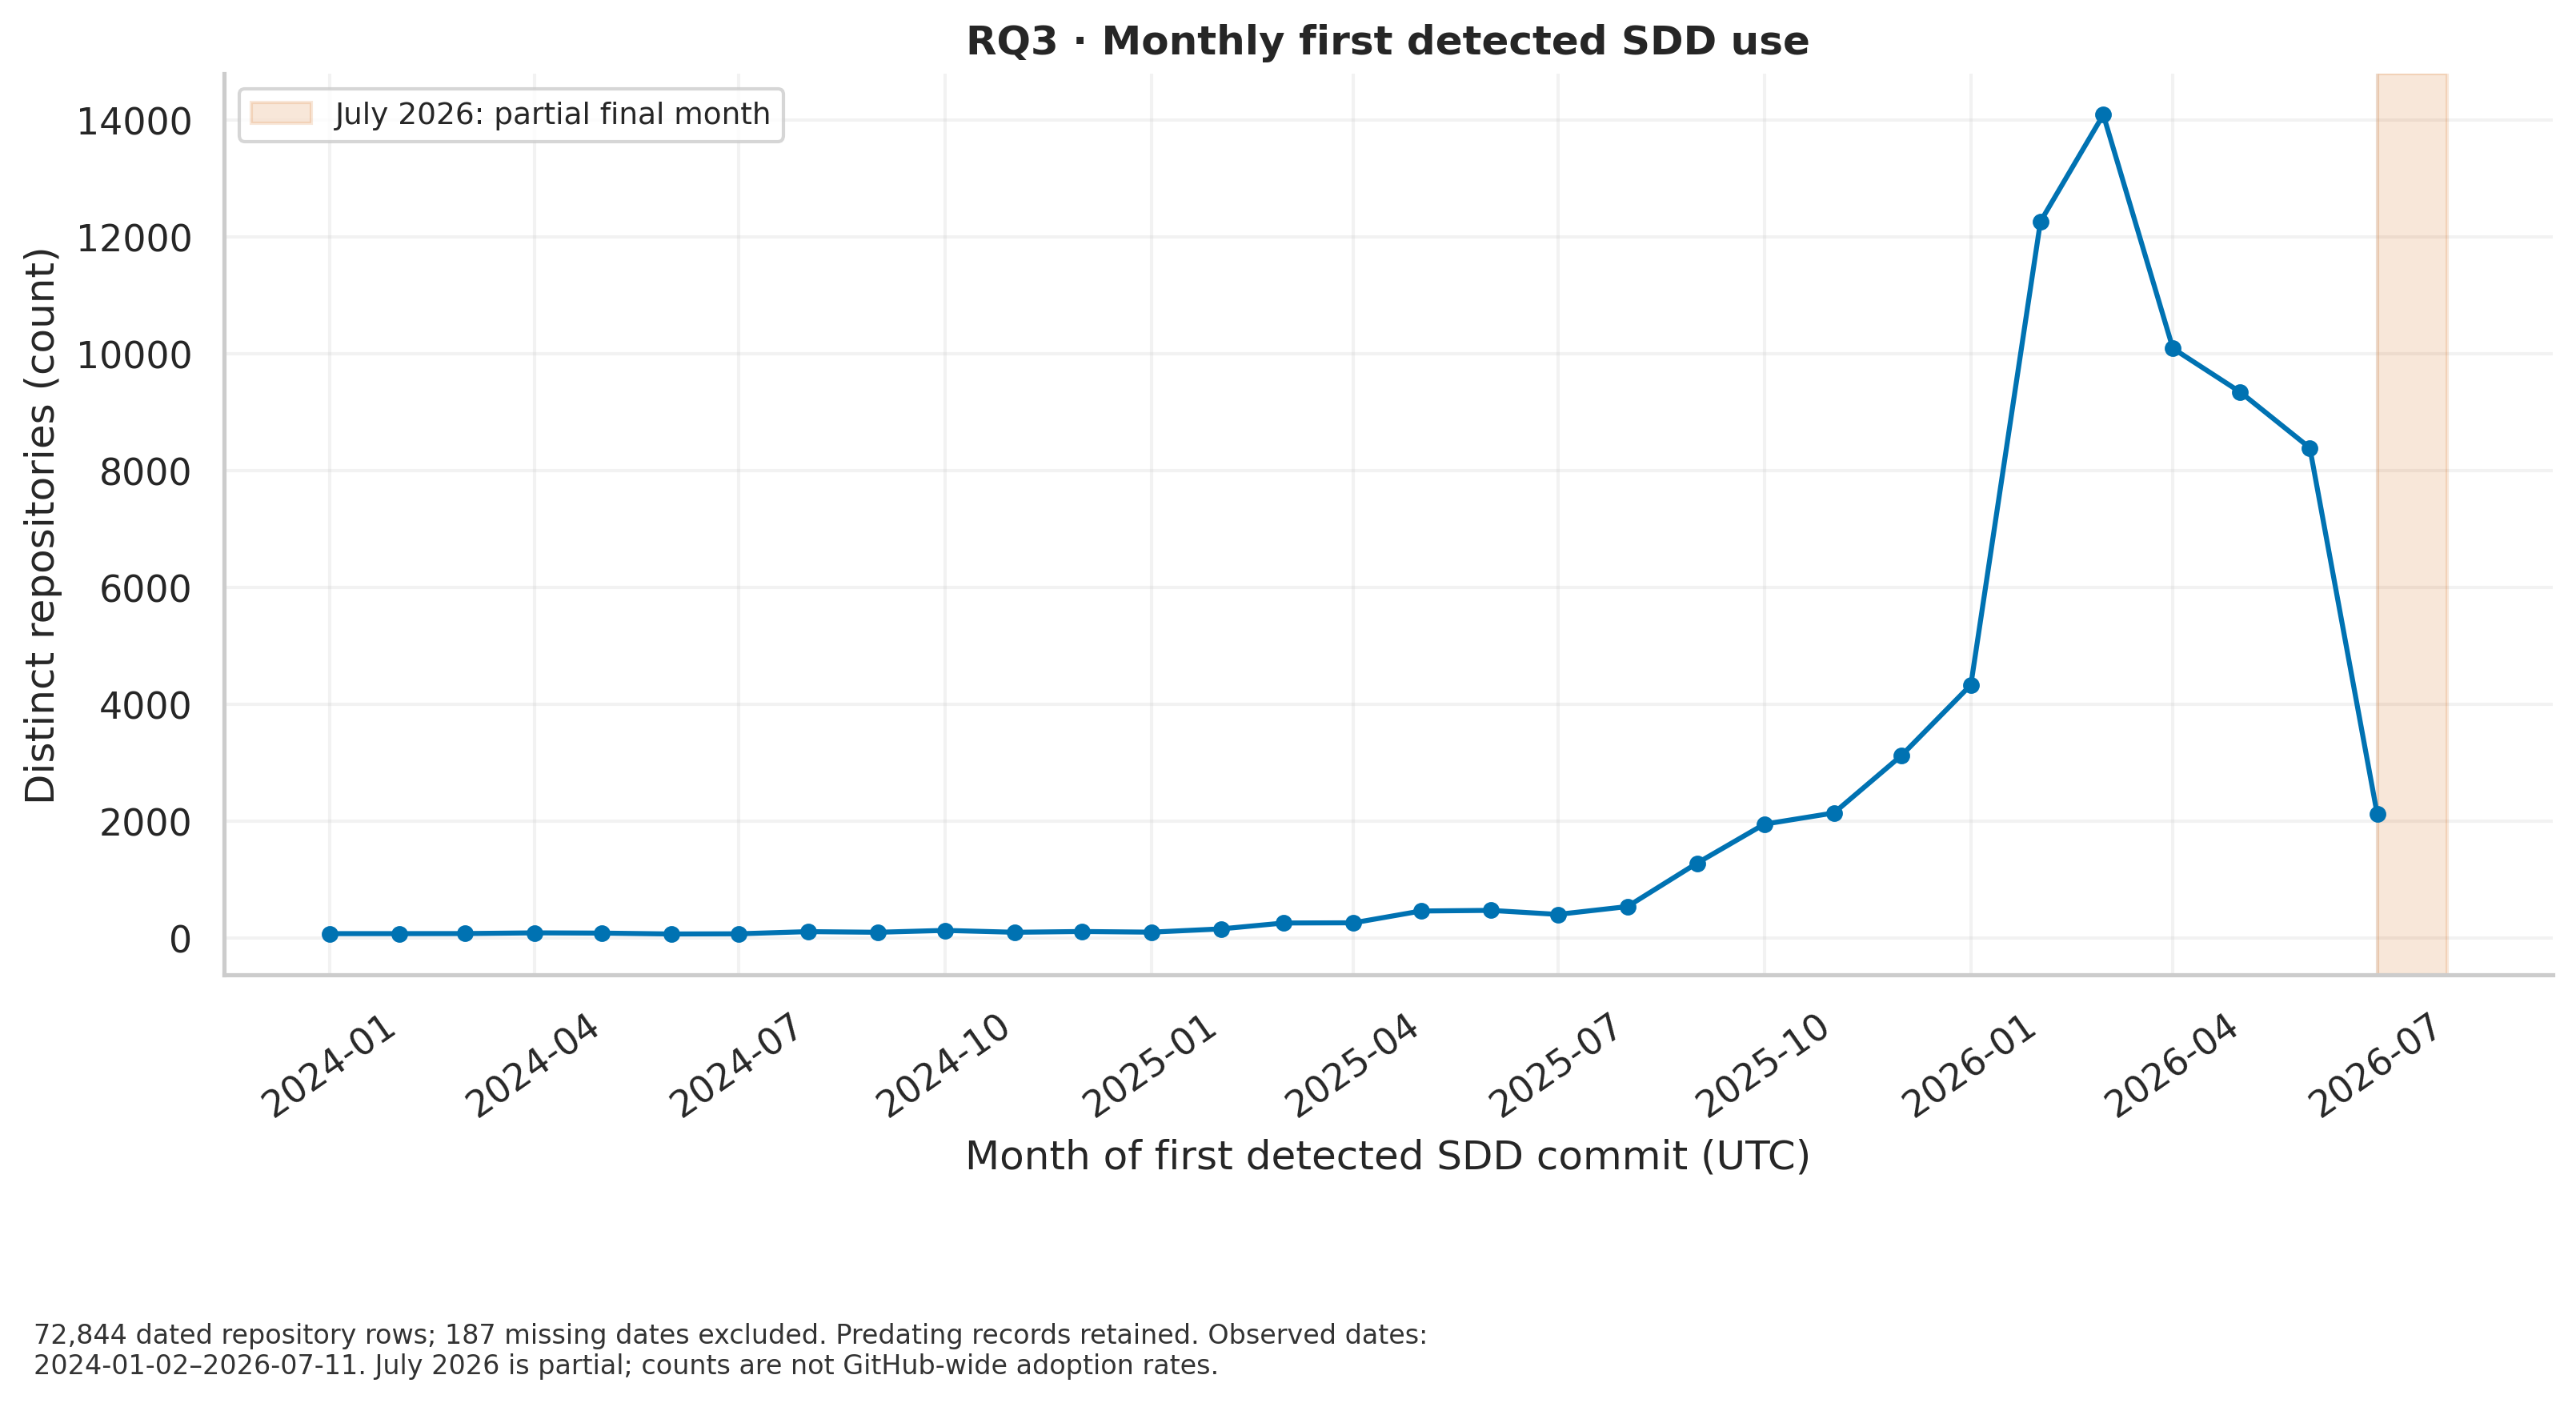

**Caption.** 72,844 dated repository rows; 187 missing dates excluded. Predating records retained. Observed dates: 2024-01-02–2026-07-11. July 2026 is partial; counts are not GitHub-wide adoption rates.

**Interpretation.** The largest count before the partial final month is 14,093 in March 2026. A lower partial-month count cannot establish a decline in adoption.

In [13]:
show(rp.monthly_adoption(r, OUT))

### Annual repository first detections

,repositories
year,
2024.0,1073
2025.0,11130
2026.0,60641


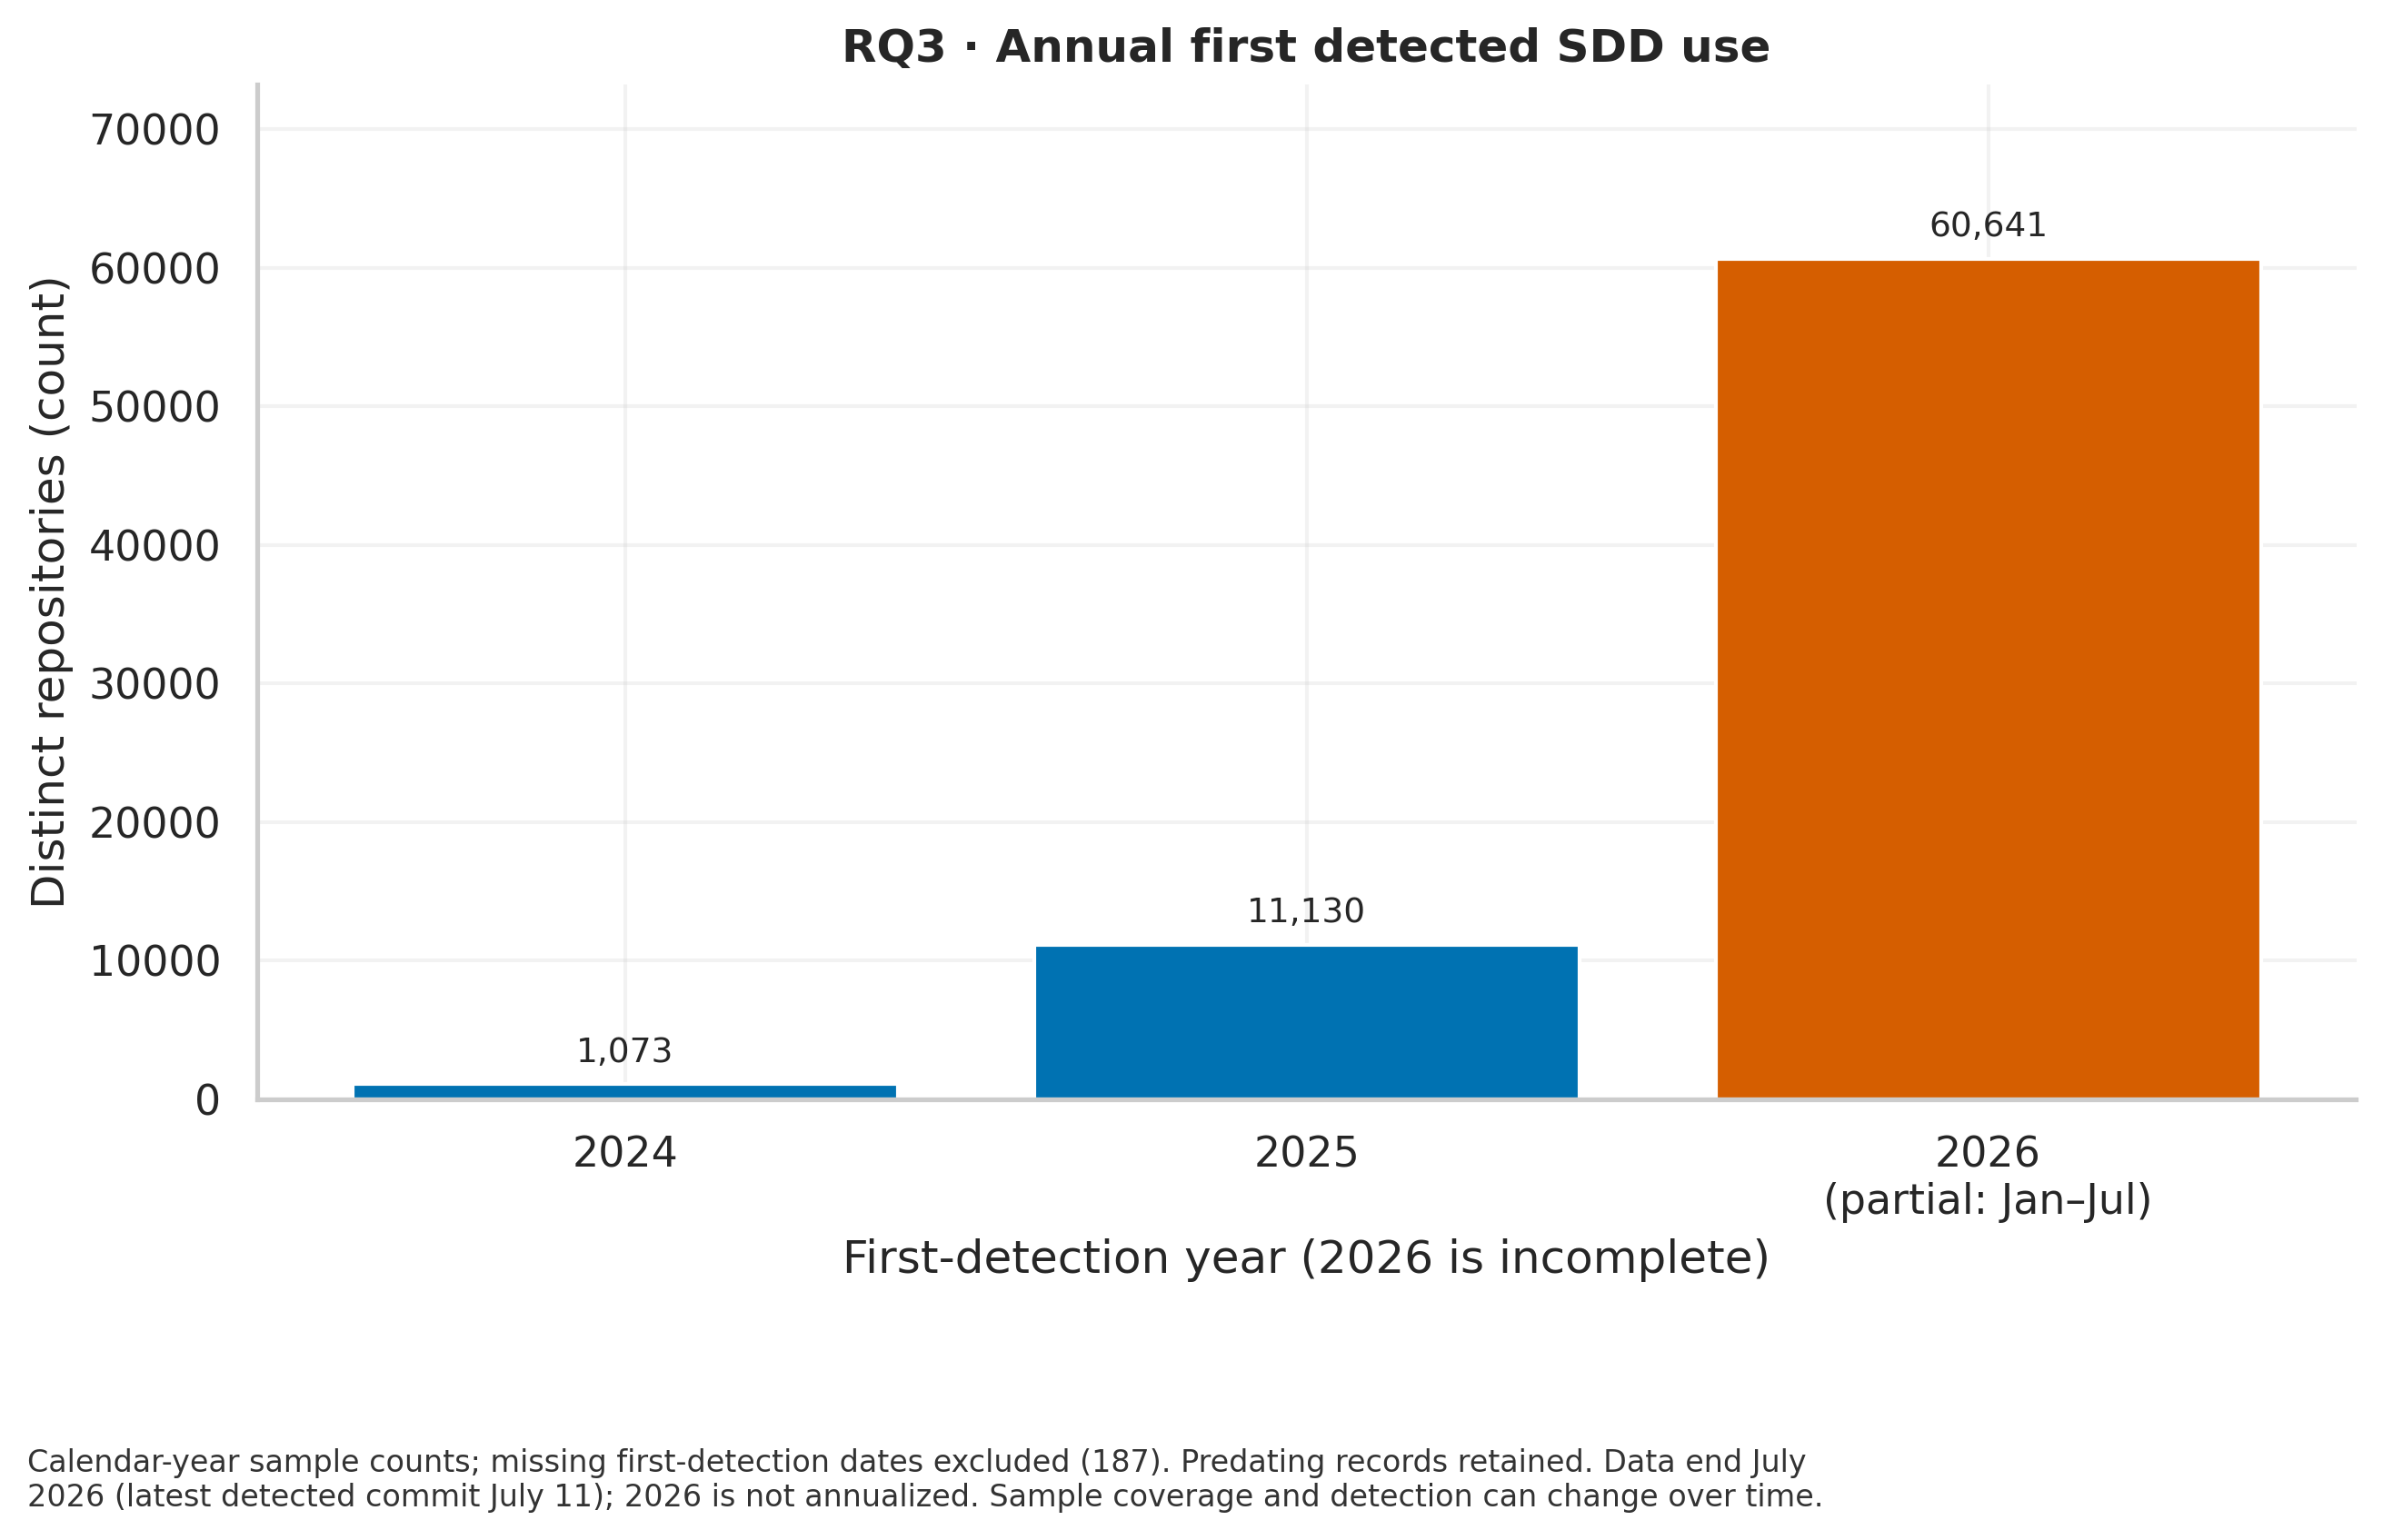

**Caption.** Calendar-year sample counts; missing first-detection dates excluded (187). Predating records retained. Data end July 2026 (latest detected commit July 11); 2026 is not annualized. Sample coverage and detection can change over time.

**Interpretation.** 2024: 1,073; 2025: 11,130; 2026: 60,641. The incomplete 2026 count is not directly comparable to a full calendar year; no GitHub-wide denominator is available.

In [14]:
display(tables['annual_repository_counts'])
show(rp.annual_adoption(r, OUT))

### Common detected SDD categories

,grain,variable,n_non_null,n_missing,median,mean,q25,q75,maximum
7,repository-category,num_specs_for_tool,75866,0,1.0,6.205613,1.0,2.0,2708.0


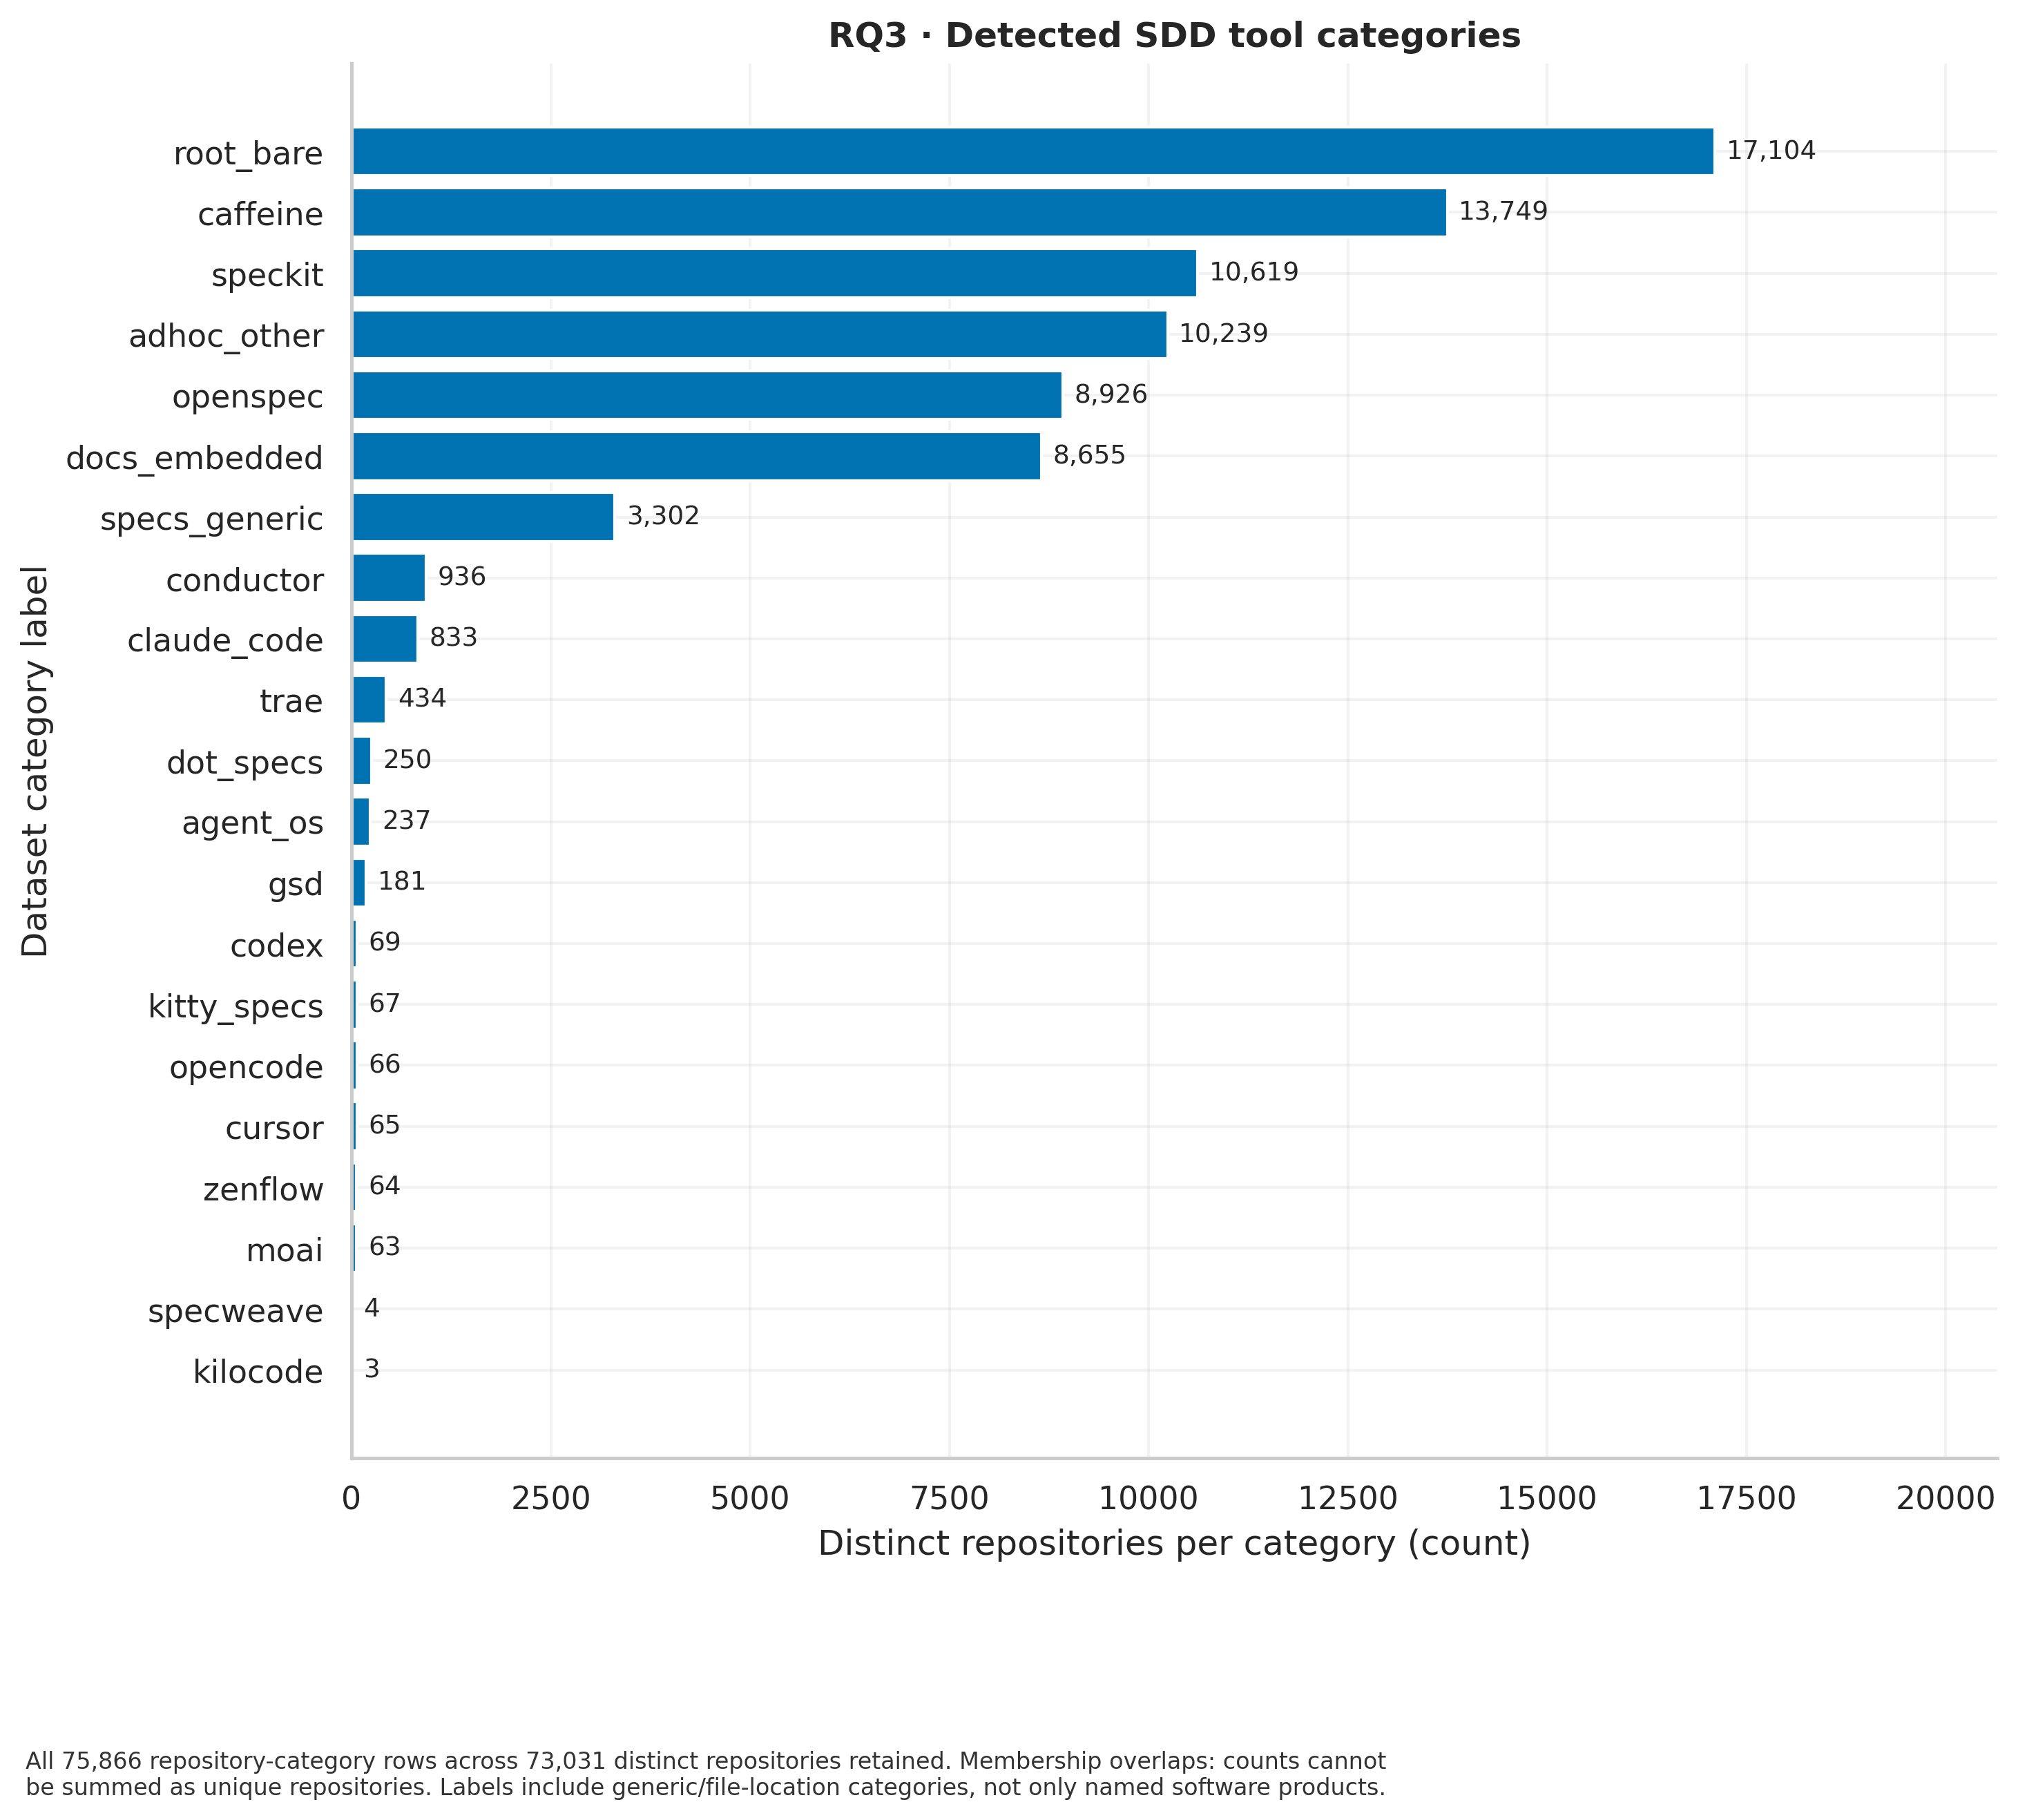

**Caption.** All 75,866 repository-category rows across 73,031 distinct repositories retained. Membership overlaps: counts cannot be summed as unique repositories. Labels include generic/file-location categories, not only named software products.

**Interpretation.** The leading category is root_bare (17,104 repositories). There are 21 category labels. root_bare and docs_embedded describe detection categories and must not be described as software products.

In [15]:
display(tables['numeric_summary'].query("variable == 'num_specs_for_tool'"))
show(tp.common_categories(t, OUT))

### Monthly first detections for leading categories

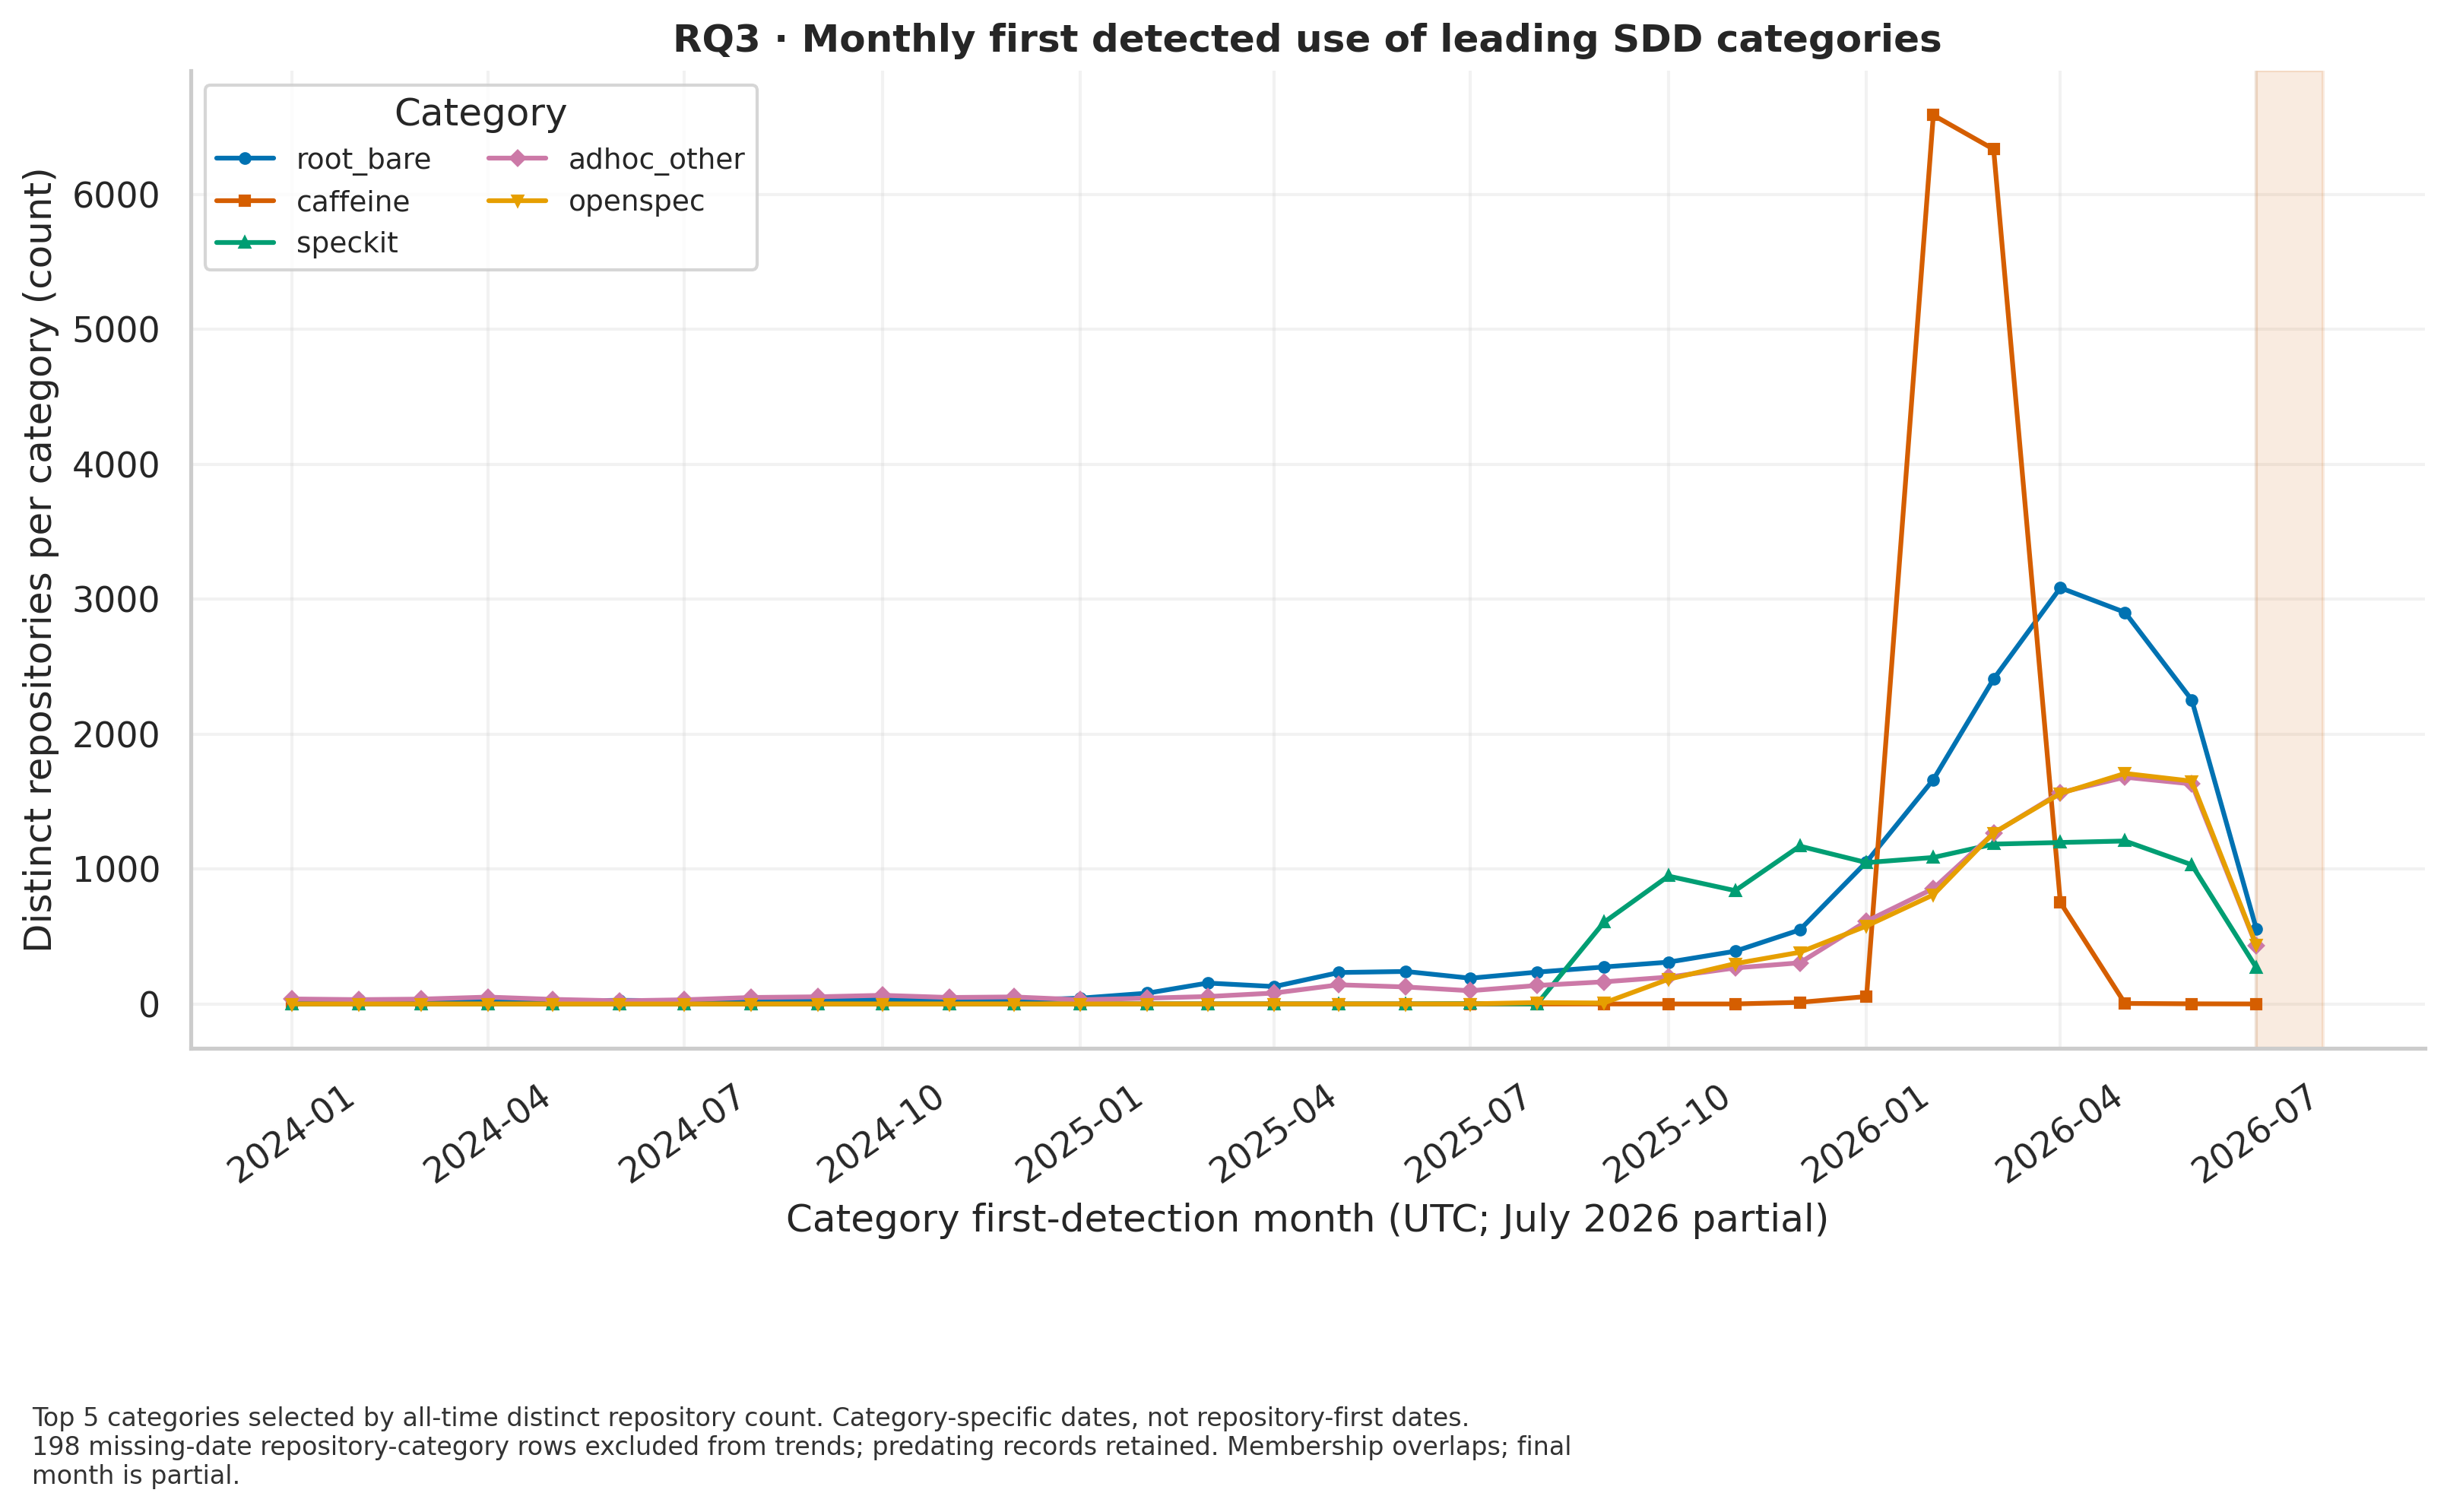

**Caption.** Top 5 categories selected by all-time distinct repository count. Category-specific dates, not repository-first dates. 198 missing-date repository-category rows excluded from trends; predating records retained. Membership overlaps; final month is partial.

**Interpretation.** The leading categories are root_bare, caffeine, speckit, adhoc_other, openspec. The trend table contains 75,668 dated repository-category records across all categories; a repository may contribute at different months for different categories. These are first detections, not monthly active usage.

In [16]:
show(tp.monthly_categories(t, OUT))

### Category presence within main programming languages

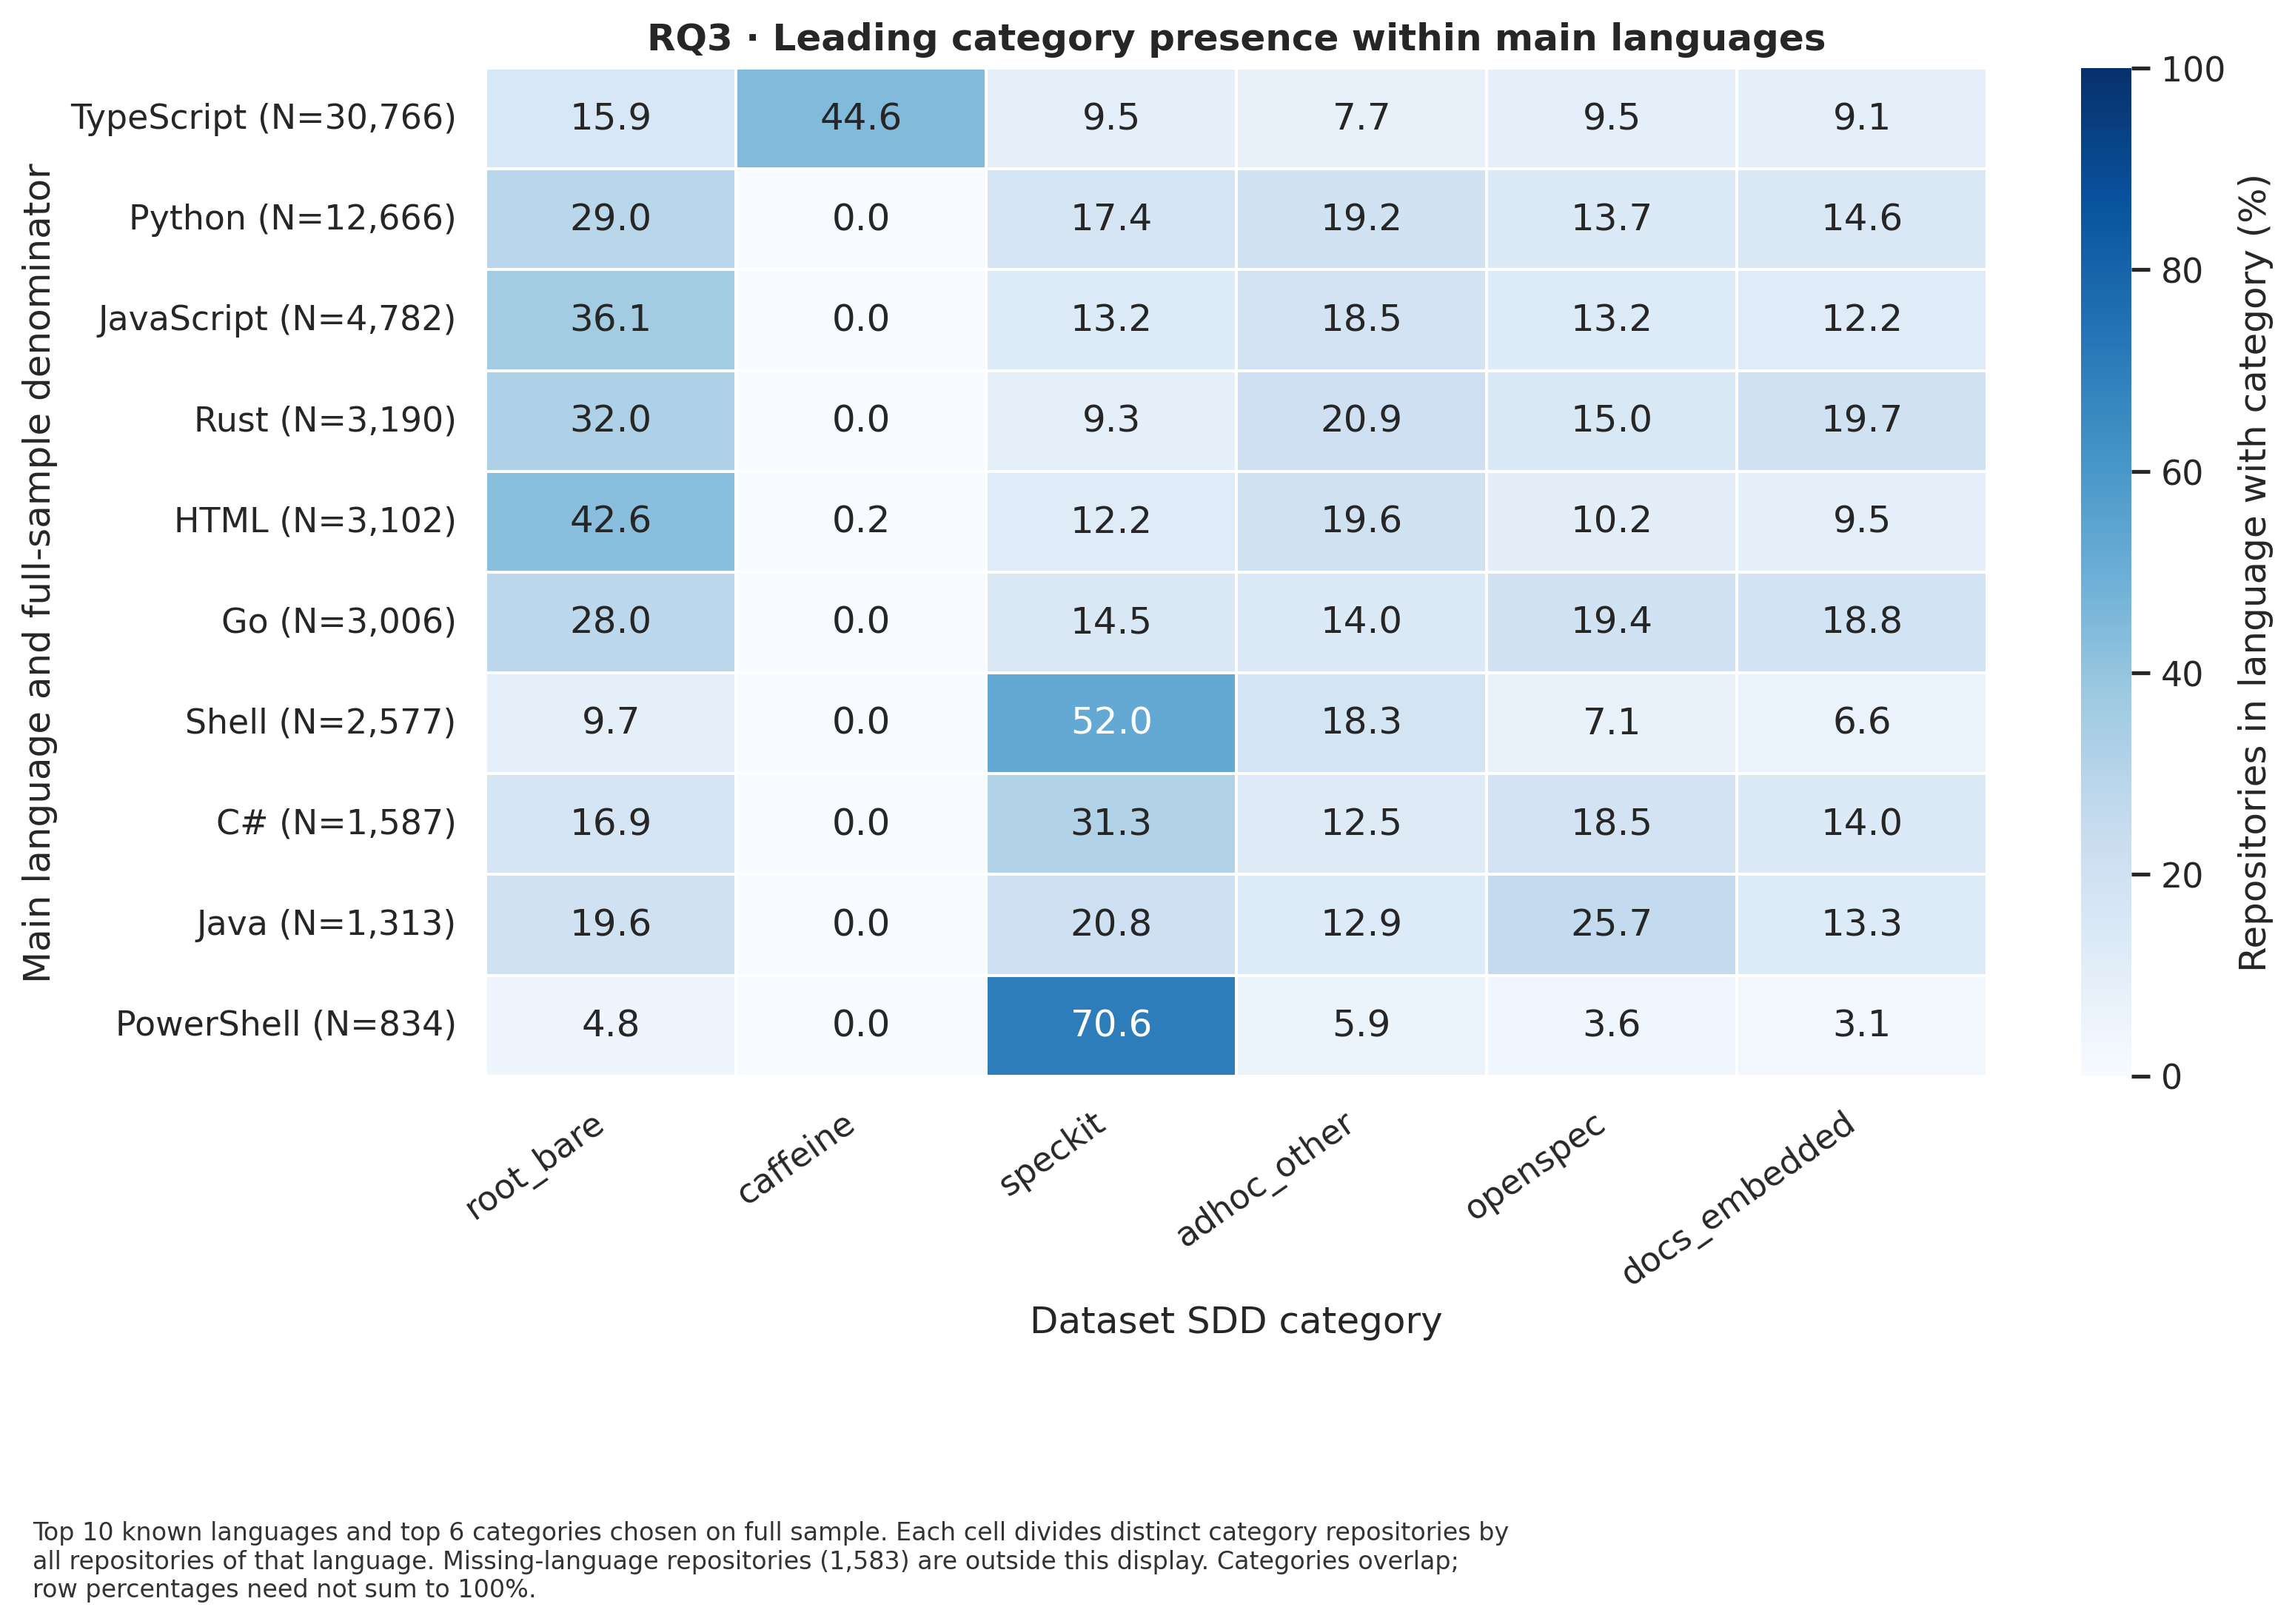

**Caption.** Top 10 known languages and top 6 categories chosen on full sample. Each cell divides distinct category repositories by all repositories of that language. Missing-language repositories (1,583) are outside this display. Categories overlap; row percentages need not sum to 100%.

**Interpretation.** The largest displayed within-language presence is speckit in PowerShell (70.6%). These conditional sample shares do not measure adoption rates among all GitHub repositories of a language.

In [17]:
show(tp.categories_by_language(r, t, OUT))

### Sensitivity to predating histories

The following table separates dated repository first detections by age status. It permits a valid-only sensitivity comparison without discarding predating records from the main time analysis. Missing-date rows cannot appear here.

In [18]:
display(tables['monthly_repository_counts_by_age_status'])

adoption_age_status,predates_repo_creation,valid
month,,
2024-01-01,16,58
2024-02-01,18,56
2024-03-01,12,63
2024-04-01,33,54
2024-05-01,21,62
2024-06-01,14,54
2024-07-01,16,55
2024-08-01,28,80
2024-09-01,20,77


## Limitations and report guidance

- The sampling frame and detection process limit generalization. There is no denominator for overall GitHub adoption, no causal comparison, and no monthly activity/retention measure.
- `repo_fork` is uniformly False/0, preventing fork-vs-non-fork comparisons. `repo_forks` is a separate numeric measure of forks received.
- Missing languages are an explicit bucket in RQ1. Language comparisons use top known languages with stated denominators. Category memberships overlap; within-language percentages need not sum to 100%.
- Stars and forks are snapshot counts. Main language is not a full language inventory. Specifications and contributors reflect detected files and logged-in accounts.
- Ages are conditional on usable chronology; per-group exclusion counts should accompany comparisons. Imported/migrated histories may help explain predating commits but cannot be established from these tables.
- Use medians/IQRs with full-tail means/maxima; log1p plots preserve zero. Do not interpret the partial final-month drop as an adoption decline or annualize 2026 without verified coverage.

Run `python -m src.pipeline` to regenerate all tables, figures and the dynamic `ANALYSIS_FINDINGS.md`. See `DATA_VALIDATION.md` and `results/validation_report.json` for the validation audit.